# Tái hiện framework dự báo tiêu thụ năng lượng trên `KAG_energydata_complete.csv`

**Bài báo tham chiếu:** Eskandari et al. (2024), *Innovative framework for accurate and transparent forecasting of energy consumption: A fusion of feature selection and interpretable machine learning*, Applied Energy, 366, 123314. DOI: `10.1016/j.apenergy.2024.123314`.

**Dataset thực nghiệm:** `KAG_energydata_complete.csv` — 19.735 quan sát, chu kỳ ghi nhận 10 phút, target `Appliances`.

**Bài toán:** dự báo `Appliances(t+1)` từ thông tin tại thời điểm `t`; một bước dự báo tương ứng 10 phút.

**Thiết kế:** phương pháp tái hiện được triển khai trong Python trên dataset khác với dataset gốc. Kết quả chỉ phục vụ đánh giá framework trên dữ liệu KAG, không phải replication các trị số trong bài báo.

## Phạm vi phương pháp, ánh xạ dữ liệu và giới hạn tái hiện

### Framework tham chiếu

- Tiền xử lý, phân tích tương quan Pearson, lựa chọn đặc trưng và chuẩn hóa dữ liệu.
- `Ensemble filter` với bốn base methods: `mRMR`, `Random Forest`, `Relief`, `F-test FS`.
- Ba nhánh Feature Selection: `Ensemble filter (S1)`, `Wrapper (S2)` và `Ensemble filter-Wrapper (S1S2)`.
- Năm mô hình: `LASSO`, `SVR-Linear`, `SVR-RBF`, `GPR`, `LSBoost`.
- `Bayesian Optimization`, đánh giá bằng RMSE, rRMSE, MAPE, MAE và R²; giải thích bằng `SHAP`.

### Ánh xạ dataset

| Thành phần | Bài báo | Dataset KAG | Ánh xạ trong notebook |
|---|---|---|---|
| Target | `EC(t+1)` | `Appliances` | `Appliances(t+1)` |
| Tần suất | Monthly | 10 phút | Một bước dự báo = 10 phút |
| Temporal features | `Mon#`, `SinM`, `CosM` | Thời gian ngày/tuần có tính chu kỳ | Giữ month encoding; bổ sung hour/day-of-week encoding |
| Candidate features | 18 biến theo domain knowledge | Sensor, thời tiết, `lights`, lag target và temporal features | Dùng biến số hợp lệ của KAG; không tạo biến kinh tế không có trong dataset |
| Relief | `Relief` | Target liên tục | Dùng `RReliefF`, biến thể regression |
| Split | 80/20 | Chuỗi thời gian | Chronological 80/20; scaler chỉ fit trên train |

### Các sai khác không thể khẳng định tương đương 100%

1. Dataset, miền dữ liệu, tần suất và target khác nghiên cứu gốc; do đó các trị số metric không thể so sánh trực tiếp với Table 7.
2. Bài báo công bố relative importance, voting và average importance, nhưng không mô tả đầy đủ toàn bộ quy tắc chuẩn hóa điểm số nội bộ của từng base method. Notebook dùng min–max relative importance cho score thô; `mRMR` dùng relative rank score. Đây là lựa chọn triển khai minh bạch, không phải khẳng định trùng hoàn toàn mã MATLAB.
3. `Relief` được ánh xạ sang `RReliefF` do target regression.
4. `SIFE` là Python port theo mô tả và tham số công bố; fuzzy granulation được xấp xỉ bằng diversity theo Jaccard distance. Đây không phải source MATLAB gốc.
5. `GPR` dùng Gaussian Process với RBF kernel và giới hạn số hàng huấn luyện; không tái tạo chính xác `Subset of regressors`, `Pure Quadratic` basis và `Sigma` trong MATLAB.
6. `LSBoost` dùng `GradientBoostingRegressor`; đây là ánh xạ gần đúng cho số learning cycles, learning rate và số splits, không phải cùng implementation MATLAB. Final fit của `SVR` dùng tối đa 2.500 hàng được lấy mẫu đều theo thời gian để giới hạn độ phức tạp tính toán.
7. `Bayesian Optimization` dùng `BayesSearchCV` cùng `TimeSeriesSplit`, tối đa 2.500 hàng training được lấy mẫu theo thời gian; không phải Bayesian Optimization toolbox của MATLAB R2023b.
8. Feature temporal `Hour#`, `SinH`, `CosH`, `DOW#`, `SinDOW`, `CosDOW` là mở rộng cho chuỗi 10 phút, không thuộc đặc tả monthly trong bài báo.
9. Outlier Analysis và các baseline thông thường là phần bổ sung cho dataset KAG, không được xem là thành phần nguyên bản của framework.

## Giai đoạn A — Chuẩn hóa dữ liệu và tái hiện Feature Selection

Giai đoạn A bao gồm kiểm tra chất lượng dữ liệu, phân tích outlier, xây dựng supervised time series, chronological split, scaling và tái hiện ba nhánh Feature Selection: `Ensemble filter` (`S1`), `Wrapper` (`S2`) và `Hybrid Ensemble Filter–Wrapper` (`S1S2`). `S1` là candidate pool đầu vào của nhánh hybrid; `S2` được tối ưu trên toàn bộ candidate features.


## Môi trường thực nghiệm Python

Notebook được triển khai trên Python 3.11 trong môi trường ảo `.venv` của project. Các phiên bản thư viện được cố định trong `requirements.txt`; Jupyter kernel `Python 3.11 (energy-forecasting)` được đăng ký riêng cho workspace.


In [169]:
import importlib.util

required_modules = {
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "sklearn": "scikit-learn",
    "joblib": "joblib",
    "pyarrow": "pyarrow",
    "shap": "shap",
    "skopt": "scikit-optimize",
    "scipy": "scipy",
    "ipykernel": "ipykernel",
}
missing_modules = [package for module, package in required_modules.items()
                   if importlib.util.find_spec(module) is None]
if missing_modules:
    raise ModuleNotFoundError(
        "Thiếu thư viện: " + ", ".join(missing_modules) +
        ". Cài đặt bằng: python -m pip install -r requirements.txt"
    )
print("Dependency check: passed")

Dependency check: passed


## Cấu trúc workspace local

```text
energy_forecasting_vscode/
├── data/raw/                  # CSV đầu vào
├── notebooks/                 # Notebook thực nghiệm
├── outputs/quick/             # Kết quả smoke test
├── outputs/paper/             # Kết quả thực nghiệm chính thức
├── backups/                   # Bản sao lưu kết quả
├── requirements.txt
├── setup_windows.ps1
└── README_VSCODE.md
```

Mỗi `EXPERIMENT_MODE` ghi vào một thư mục output riêng; các checkpoint của `quick` không được dùng làm checkpoint của `paper`.

In [170]:
from pathlib import Path
import os, shutil, json, time, platform, warnings, random, hashlib
import numpy as np
import pandas as pd

# Local project root: hỗ trợ chạy notebook từ thư mục gốc hoặc notebooks/.
CURRENT_DIR = Path.cwd().resolve()
if CURRENT_DIR.name.lower() == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

PROJECT_NAME = "energy_forecasting_reproduction"
EXPERIMENT_REVISION = "ABC-1.2"
EXPERIMENT_MODE = "paper"  # Đổi thành "paper" cho thực nghiệm chính thức.
RANDOM_SEED = 42
TEST_SIZE = 0.20
TARGET_RAW = "Appliances"
TIME_COL = "date"
N_FILTER_FEATURES = 10
MIN_VOTES = 2

if EXPERIMENT_MODE == "quick":
    SIFE_POPULATION = 12
    SIFE_ITERATIONS = 3
    SIFE_EVAL_MAX_ROWS = 1000
    BAYES_MAX_TRAIN_ROWS = 1500
    SVR_MAX_TRAIN_ROWS = 1500
    RRELIEFF_UPDATES = 800
    BAYES_ITERATIONS = 3
    BAYES_CV_SPLITS = 2
    SHAP_BACKGROUND_ROWS = 25
    SHAP_EXPLAIN_ROWS = 20
elif EXPERIMENT_MODE == "paper":
    SIFE_POPULATION = 120
    SIFE_ITERATIONS = 60
    SIFE_EVAL_MAX_ROWS = 1500
    BAYES_MAX_TRAIN_ROWS = 2500
    SVR_MAX_TRAIN_ROWS = 2500
    RRELIEFF_UPDATES = 4000
    BAYES_ITERATIONS = 20
    BAYES_CV_SPLITS = 3
    SHAP_BACKGROUND_ROWS = 40
    SHAP_EXPLAIN_ROWS = 30
else:
    raise ValueError("EXPERIMENT_MODE chỉ nhận 'quick' hoặc 'paper'.")

RUN_ROOT = PROJECT_ROOT / "outputs" / EXPERIMENT_MODE
PATHS = {
    "raw": PROJECT_ROOT / "data" / "raw",
    "processed": RUN_ROOT / "data" / "processed",
    "checkpoints": RUN_ROOT / "artifacts" / "checkpoints",
    "feature_selection": RUN_ROOT / "artifacts" / "feature_selection",
    "models": RUN_ROOT / "artifacts" / "models",
    "metrics": RUN_ROOT / "artifacts" / "metrics",
    "figures": RUN_ROOT / "figures",
    "logs": RUN_ROOT / "logs",
    "reports": RUN_ROOT / "reports",
    "config": RUN_ROOT / "config",
}
for folder in PATHS.values():
    folder.mkdir(parents=True, exist_ok=True)

DATA_PATH = PATHS["raw"] / "KAG_energydata_complete.csv"
CONFIG = {
    "project_name": PROJECT_NAME,
    "experiment_revision": EXPERIMENT_REVISION,
    "experiment_mode": EXPERIMENT_MODE,
    "random_seed": RANDOM_SEED,
    "test_size": TEST_SIZE,
    "target_raw": TARGET_RAW,
    "time_col": TIME_COL,
    "forecast_horizon_steps": 1,
    "sampling_interval_minutes": 10,
    "n_filter_features": N_FILTER_FEATURES,
    "minimum_votes": MIN_VOTES,
    "SIFE_population": SIFE_POPULATION,
    "SIFE_iterations": SIFE_ITERATIONS,
    "SIFE_crossover_probability": 0.6,
    "SIFE_mutation_probability": 0.5,
    "SIFE_w1_error": 0.80,
    "SIFE_w2_subset_size": 0.20,
    "SIFE_eval_max_rows": SIFE_EVAL_MAX_ROWS,
    "Bayesian_Optimization_max_train_rows": BAYES_MAX_TRAIN_ROWS,
    "SVR_max_train_rows": SVR_MAX_TRAIN_ROWS,
    "RReliefF_updates": RRELIEFF_UPDATES,
    "Bayesian_Optimization_iterations": BAYES_ITERATIONS,
    "Bayesian_Optimization_cv_splits": BAYES_CV_SPLITS,
    "SHAP_background_rows": SHAP_BACKGROUND_ROWS,
    "SHAP_explain_rows": SHAP_EXPLAIN_ROWS,
}
(PATHS["config"] / "experiment_config.json").write_text(
    json.dumps(CONFIG, ensure_ascii=False, indent=2), encoding="utf-8"
)
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
print("Project root:", PROJECT_ROOT)
print("Run root:", RUN_ROOT)
print("Experiment mode:", EXPERIMENT_MODE)
print("Dataset exists:", DATA_PATH.exists())

Project root: D:\LMS\dubao\energy_forecasting_vscode_project\energy_forecasting_vscode
Run root: D:\LMS\dubao\energy_forecasting_vscode_project\energy_forecasting_vscode\outputs\paper
Experiment mode: paper
Dataset exists: True


In [171]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Không tìm thấy dataset: {DATA_PATH}\n"
        "Đặt KAG_energydata_complete.csv vào data/raw/ hoặc sửa DATA_PATH trong cell cấu hình."
    )
print(f"Dataset source: {DATA_PATH}")
print(f"Dataset size: {DATA_PATH.stat().st_size / (1024**2):.2f} MB")

Dataset source: D:\LMS\dubao\energy_forecasting_vscode_project\energy_forecasting_vscode\data\raw\KAG_energydata_complete.csv
Dataset size: 11.42 MB


## Chế độ thực nghiệm và ngân sách tính toán

`quick` là smoke test với population, số iterations, Bayesian search và SHAP được giảm. `paper` giữ `SIFE` population size 120, maximum iteration 60, crossover probability 0.6, mutation probability 0.5; Bayesian Optimization dùng 20 iterations và 3 folds. Do KAG có gần 20 nghìn quan sát, các tác vụ có độ phức tạp cao được chạy trên mẫu thời gian phân bố đều: `SIFE` tối đa 1.500 hàng, Bayesian search tối đa 2.500 hàng và `SVR` final fit tối đa 2.500 hàng trong chế độ `paper`. `GPR` cũng dùng giới hạn số hàng nội tại. Các giới hạn là adaptation tính toán cho dữ liệu KAG, không phải thông số được báo cáo trong bài báo; chúng được ghi trong `experiment_config.json` và `run_manifest.json`.

Các model reference settings được ánh xạ sang scikit-learn. `Bayesian Optimization` chỉ sử dụng training partition; holdout test không tham gia lựa chọn hyperparameters. Các fitted estimators được checkpoint theo revision, fingerprint dataset, feature subset và estimator parameters để có thể tiếp tục từ phần đã hoàn tất.


In [172]:
print("Experiment configuration loaded from cell 6.")
print(json.dumps(CONFIG, ensure_ascii=False, indent=2))
assert SIFE_POPULATION == (12 if EXPERIMENT_MODE == "quick" else 120)
assert SIFE_ITERATIONS == (3 if EXPERIMENT_MODE == "quick" else 60)
print("Resource caps:", {"SIFE": SIFE_EVAL_MAX_ROWS, "Bayesian Optimization": BAYES_MAX_TRAIN_ROWS, "SVR": SVR_MAX_TRAIN_ROWS})


Experiment configuration loaded from cell 6.
{
  "project_name": "energy_forecasting_reproduction",
  "experiment_revision": "ABC-1.2",
  "experiment_mode": "paper",
  "random_seed": 42,
  "test_size": 0.2,
  "target_raw": "Appliances",
  "time_col": "date",
  "forecast_horizon_steps": 1,
  "sampling_interval_minutes": 10,
  "n_filter_features": 10,
  "minimum_votes": 2,
  "SIFE_population": 120,
  "SIFE_iterations": 60,
  "SIFE_crossover_probability": 0.6,
  "SIFE_mutation_probability": 0.5,
  "SIFE_w1_error": 0.8,
  "SIFE_w2_subset_size": 0.2,
  "SIFE_eval_max_rows": 1500,
  "Bayesian_Optimization_max_train_rows": 2500,
  "SVR_max_train_rows": 2500,
  "RReliefF_updates": 4000,
  "Bayesian_Optimization_iterations": 20,
  "Bayesian_Optimization_cv_splits": 3,
  "SHAP_background_rows": 40,
  "SHAP_explain_rows": 30
}
Resource caps: {'SIFE': 1500, 'Bayesian Optimization': 2500, 'SVR': 2500}


## 5. Import thư viện và thiết lập reproducibility

Các hàm và biến được đặt tên theo vai trò kỹ thuật. Các bước có tính ngẫu nhiên đều nhận `RANDOM_SEED`. Khi báo cáo kết quả, lưu lại phiên bản thư viện cùng cấu hình đã chạy.

In [173]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn
import shap

from datetime import datetime
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.preprocessing import MinMaxScaler
from sklearn.feature_selection import mutual_info_regression, f_regression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.linear_model import Lasso, Ridge
from sklearn.svm import SVR
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score
from sklearn.inspection import permutation_importance
from scipy.stats import randint, loguniform

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 5)

print("Python:", platform.python_version())
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("SHAP:", shap.__version__)

Python: 3.11.9
pandas: 2.2.3
NumPy: 1.26.4
scikit-learn: 1.5.2
SHAP: 0.46.0


## 6. Đọc dataset và kiểm tra chất lượng dữ liệu

Ở bước này chỉ đọc CSV được chỉ định. Chưa xóa dòng hay thay đổi giá trị. Ta kiểm tra schema, kiểu dữ liệu, missing values, duplicate rows, duplicate timestamps, thứ tự thời gian và sampling interval trước khi quyết định preprocessing.

In [174]:
# Content fingerprint used to validate reusable checkpoints and fitted estimators.
_file_hash = hashlib.sha256()
with DATA_PATH.open("rb") as _data_stream:
    for _chunk in iter(lambda: _data_stream.read(1024 * 1024), b""):
        _file_hash.update(_chunk)
DATASET_SHA256 = _file_hash.hexdigest()

df_raw = pd.read_csv(DATA_PATH)

if TIME_COL not in df_raw.columns:
    raise KeyError(f"Không tìm thấy cột thời gian '{TIME_COL}'. Columns: {df_raw.columns.tolist()}")
if TARGET_RAW not in df_raw.columns:
    raise KeyError(f"Không tìm thấy target '{TARGET_RAW}'.")

df_raw[TIME_COL] = pd.to_datetime(df_raw[TIME_COL], errors="coerce")
invalid_timestamp_rows = int(df_raw[TIME_COL].isna().sum())
if invalid_timestamp_rows:
    raise ValueError(
        f"Found {invalid_timestamp_rows} rows with invalid timestamps; "
        "resolve them explicitly rather than silently deleting records."
    )
df_raw = df_raw.sort_values(TIME_COL).reset_index(drop=True)

# Verify the nominal 10-minute sampling interval before constructing the next-step target.
time_deltas = df_raw[TIME_COL].diff().dropna()
expected_delta = pd.Timedelta(minutes=10)
if not time_deltas.eq(expected_delta).all():
    counts = time_deltas.value_counts().head(10).to_dict()
    raise ValueError(
        "Timestamp spacing is not uniformly 10 minutes. "
        f"Observed intervals: {counts}. Resolve the time index before one-step forecasting."
    )

print("Dataset SHA256:", DATASET_SHA256)
print("Shape:", df_raw.shape)
print("Date range:", df_raw[TIME_COL].min(), "->", df_raw[TIME_COL].max())
display(df_raw.head())
display(df_raw.dtypes.rename("dtype").to_frame())

Dataset SHA256: 2820bf712ad0275cb18b85a05250926100d8e65ebb9f4d2d016ca91ea152a25d
Shape: (19735, 29)
Date range: 2016-01-11 17:00:00 -> 2016-05-27 18:00:00


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


,dtype
date,datetime64[ns]
Appliances,int64
lights,int64
T1,float64
RH_1,float64
T2,float64
RH_2,float64
T3,float64
RH_3,float64
T4,float64


In [175]:
missing_table = df_raw.isna().sum().sort_values(ascending=False).rename("missing_count").to_frame()
missing_table["missing_pct"] = 100 * missing_table["missing_count"] / len(df_raw)

row_duplicates = int(df_raw.duplicated().sum())
time_duplicates = int(df_raw[TIME_COL].duplicated().sum())
intervals = df_raw[TIME_COL].diff().dropna()
interval_counts = intervals.value_counts().head(10)

quality_summary = {
    "rows": int(len(df_raw)),
    "columns": int(df_raw.shape[1]),
    "missing_cells": int(df_raw.isna().sum().sum()),
    "duplicate_rows": row_duplicates,
    "duplicate_timestamps": time_duplicates,
    "timestamp_monotonic_increasing": bool(df_raw[TIME_COL].is_monotonic_increasing),
    "most_common_interval": str(interval_counts.index[0]) if len(interval_counts) else None,
    "interval_unique_count": int(intervals.nunique()),
}

display(missing_table)
print(json.dumps(quality_summary, ensure_ascii=False, indent=2))
print("Most common time intervals:")
display(interval_counts.rename("count").to_frame())

with open(PATHS["reports"] / "data_quality_summary.json", "w", encoding="utf-8") as f:
    json.dump(quality_summary, f, ensure_ascii=False, indent=2)
missing_table.to_csv(PATHS["reports"] / "missing_values.csv")

,missing_count,missing_pct
date,0,0.0
T7,0,0.0
rv1,0,0.0
Tdewpoint,0,0.0
Visibility,0,0.0
Windspeed,0,0.0
RH_out,0,0.0
Press_mm_hg,0,0.0
T_out,0,0.0
RH_9,0,0.0


{
  "rows": 19735,
  "columns": 29,
  "missing_cells": 0,
  "duplicate_rows": 0,
  "duplicate_timestamps": 0,
  "timestamp_monotonic_increasing": true,
  "most_common_interval": "0 days 00:10:00",
  "interval_unique_count": 1
}
Most common time intervals:


,count
date,
0 days 00:10:00,19734


### 6.1. Xử lý cột trùng và dữ liệu thời gian

Kiểm tra dataset cho thấy `rv1` và `rv2` có thể trùng nhau hoàn toàn. Chỉ loại `rv2` nếu chúng thực sự giống nhau ở tất cả các dòng; không tự ý loại các sensor khác chỉ vì tương quan cao. Dữ liệu được sắp xếp theo `date`, không nội suy vì bước kiểm tra ban đầu cho thấy chuỗi cách đều 10 phút và không có missing values.

In [176]:
df = df_raw.copy()

if "rv1" in df.columns and "rv2" in df.columns:
    rv_identical = bool(df["rv1"].equals(df["rv2"]))
else:
    rv_identical = False

if rv_identical:
    df = df.drop(columns=["rv2"])
    print("Đã loại rv2 vì trùng tuyệt đối với rv1.")
else:
    print("Không loại rv2: hai cột không trùng tuyệt đối hoặc không cùng tồn tại.")

# Dữ liệu thời gian bị trùng không được âm thầm gộp vì chưa có quy tắc aggregation từ bài báo.
if df[TIME_COL].duplicated().any():
    raise ValueError("Có duplicate timestamp. Cần xác định quy tắc xử lý trước khi tiếp tục.")

numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
if df[numeric_columns].isna().any().any():
    raise ValueError("Numeric columns chứa missing values; cần phân tích nguyên nhân trước khi impute.")

print("Shape after safe duplicate-column check:", df.shape)
print("rv1/r2 identical:", rv_identical)

Đã loại rv2 vì trùng tuyệt đối với rv1.
Shape after safe duplicate-column check: (19735, 28)
rv1/r2 identical: True


## 6.2. Outlier Analysis — phân tích giá trị ngoại lai

Outlier Analysis sử dụng quy tắc IQR để xác định các quan sát nằm ngoài khoảng tham chiếu thống kê của các biến được chỉ định. Mặc định, `Appliances` là biến được khảo sát; boxplot và bảng Q1, Q3, IQR, lower bound, upper bound, số lượng và tỷ lệ outlier được lưu phục vụ kiểm tra chất lượng dữ liệu.

Outlier không mặc nhiên đồng nghĩa với lỗi dữ liệu. Trong chuỗi tiêu thụ năng lượng, các giá trị cực trị có thể phản ánh trạng thái vận hành thực tế. `REMOVE_OUTLIERS = False` là cấu hình mặc định; dữ liệu chỉ bị loại khi công tắc được bật. Phân tích IQR là bước EDA bổ sung cho dataset KAG, không phải thành phần được mô tả trong framework gốc.

,feature,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_pct
0,Appliances,50.0,100.0,50.0,-25.0,175.0,2138,10.833544


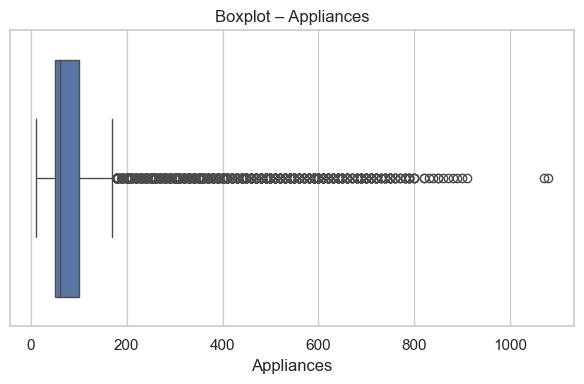

REMOVE_OUTLIERS = False
Rows flagged by IQR: 2,138 / 19,735
Outlier removal is disabled. All observations are retained.


,method,iqr_multiplier,columns,remove_outliers,rows_before,rows_flagged,rows_after
0,IQR,1.5,[Appliances],False,19735,2138,19735


In [177]:
# Outlier Analysis: IQR-based detection with an explicit deletion switch.
# Default: keep all observations. No row is removed unless the switch is enabled.

REMOVE_OUTLIERS = False
OUTLIER_COLUMNS = [TARGET_RAW]   # Default scope: target only; may be expanded deliberately.
IQR_MULTIPLIER = 1.5

# Keep an untouched copy so the original cleaned dataset remains recoverable in memory.
df_before_outlier = df.copy()

outlier_rows = []
outlier_masks = {}

for col in OUTLIER_COLUMNS:
    if col not in df_before_outlier.columns:
        print(f"Skip '{col}': column not found.")
        continue
    if not pd.api.types.is_numeric_dtype(df_before_outlier[col]):
        print(f"Skip '{col}': column is not numeric.")
        continue

    values = df_before_outlier[col].dropna()
    if values.empty:
        print(f"Skip '{col}': no valid numeric values.")
        continue

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - IQR_MULTIPLIER * iqr
    upper_bound = q3 + IQR_MULTIPLIER * iqr

    mask = (
        df_before_outlier[col].notna()
        & ((df_before_outlier[col] < lower_bound) |
           (df_before_outlier[col] > upper_bound))
    )
    outlier_masks[col] = mask
    outlier_rows.append({
        "feature": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_count": int(mask.sum()),
        "outlier_pct": float(mask.mean() * 100),
    })

outlier_summary = pd.DataFrame(outlier_rows)
display(outlier_summary)

# Visual inspection before any optional removal.
if OUTLIER_COLUMNS:
    valid_plot_cols = [
        c for c in OUTLIER_COLUMNS
        if c in df_before_outlier.columns
        and pd.api.types.is_numeric_dtype(df_before_outlier[c])
    ]
    if valid_plot_cols:
        fig, axes = plt.subplots(
            1, len(valid_plot_cols),
            figsize=(6 * len(valid_plot_cols), 4),
            squeeze=False
        )
        for ax, col in zip(axes.ravel(), valid_plot_cols):
            sns.boxplot(x=df_before_outlier[col], ax=ax)
            ax.set_title(f"Boxplot – {col}")
            ax.set_xlabel(col)
        plt.tight_layout()
        plt.show()

# Combine selected-column masks: a row is flagged if any selected column is outside its IQR bounds.
if outlier_masks:
    combined_outlier_mask = pd.concat(outlier_masks, axis=1).any(axis=1)
else:
    combined_outlier_mask = pd.Series(False, index=df_before_outlier.index)

n_flagged = int(combined_outlier_mask.sum())
print(f"REMOVE_OUTLIERS = {REMOVE_OUTLIERS}")
print(f"Rows flagged by IQR: {n_flagged:,} / {len(df_before_outlier):,}")

if REMOVE_OUTLIERS:
    df = df_before_outlier.loc[~combined_outlier_mask].copy()
    print(f"Rows removed: {n_flagged:,}")
    print(f"Rows remaining: {len(df):,}")
else:
    df = df_before_outlier.copy()
    print("Outlier removal is disabled. All observations are retained.")

# Keep an audit record for reproducibility.
outlier_audit = {
    "method": "IQR",
    "iqr_multiplier": IQR_MULTIPLIER,
    "columns": OUTLIER_COLUMNS,
    "remove_outliers": REMOVE_OUTLIERS,
    "rows_before": int(len(df_before_outlier)),
    "rows_flagged": n_flagged,
    "rows_after": int(len(df)),
}
display(pd.DataFrame([outlier_audit]))


## 7. Tạo supervised dataset và temporal features

`Appliances_t` biểu diễn mức tiêu thụ tại thời điểm hiện tại; `Appliances_t_plus_1` là target tại bản ghi kế tiếp. Dataset KAG có khoảng cách timestamp đều 10 phút, vì vậy one-step-ahead tương ứng 10 phút. `Mon#`, `SinM`, `CosM` giữ cấu trúc temporal feature của bài báo; `Hour#`, `SinH`, `CosH`, `DOW#`, `SinDOW`, `CosDOW` là các biến mở rộng phù hợp chu kỳ intraday/weekly.

In [178]:
supervised = df.copy()

# The target shift is one record ahead; verify that one record still means 10 minutes.
_supervised_delta = supervised[TIME_COL].diff().dropna()
if not _supervised_delta.eq(pd.Timedelta(minutes=10)).all():
    raise ValueError(
        "Time index is no longer regular at 10-minute intervals after preprocessing. "
        "A row deletion must not silently change the forecast horizon."
    )

dt = supervised[TIME_COL]
supervised["Appliances_t"] = supervised[TARGET_RAW]

# Month cyclic encoding: giữ đúng ý tưởng Mon#, SinM, CosM của bài báo.
supervised["Mon#"] = dt.dt.month.astype(int)
supervised["SinM"] = np.sin(2 * np.pi * (dt.dt.month - 1) / 12)
supervised["CosM"] = np.cos(2 * np.pi * (dt.dt.month - 1) / 12)

# Cyclic features bổ sung cho chu kỳ 10 phút.
minute_of_day = dt.dt.hour * 60 + dt.dt.minute
supervised["Hour#"] = dt.dt.hour.astype(int)
supervised["SinH"] = np.sin(2 * np.pi * minute_of_day / (24 * 60))
supervised["CosH"] = np.cos(2 * np.pi * minute_of_day / (24 * 60))

supervised["DOW#"] = dt.dt.dayofweek.astype(int)
supervised["SinDOW"] = np.sin(2 * np.pi * dt.dt.dayofweek / 7)
supervised["CosDOW"] = np.cos(2 * np.pi * dt.dt.dayofweek / 7)

# One-step-ahead label (10 phút tiếp theo).
supervised["Appliances_t_plus_1"] = supervised[TARGET_RAW].shift(-1)
supervised = supervised.dropna(subset=["Appliances_t_plus_1"]).reset_index(drop=True)

# Không dùng target cùng thời điểm làm input; chỉ dùng lag Appliances_t.
excluded_columns = {TIME_COL, TARGET_RAW, "Appliances_t_plus_1"}
feature_columns = [c for c in supervised.columns if c not in excluded_columns]

X_all = supervised[feature_columns].select_dtypes(include=np.number).copy()
y_all = supervised["Appliances_t_plus_1"].astype(float).copy()
time_all = supervised[TIME_COL].copy()

assert "Appliances_t" in X_all.columns
assert TARGET_RAW not in X_all.columns
assert "Appliances_t_plus_1" not in X_all.columns
assert len(X_all) == len(y_all)

print("Supervised shape:", X_all.shape)
print("Target:", "Appliances_t_plus_1")
print("Number of candidate features:", len(feature_columns))
print("Features:", feature_columns)
print("Time range:", time_all.min(), "->", time_all.max())

display(supervised[[TIME_COL, "Appliances_t", "Appliances_t_plus_1"]].head(8))
supervised.to_parquet(PATHS["processed"] / "supervised_dataset.parquet", index=False)

Supervised shape: (19734, 36)
Target: Appliances_t_plus_1
Number of candidate features: 36
Features: ['lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'rv1', 'Appliances_t', 'Mon#', 'SinM', 'CosM', 'Hour#', 'SinH', 'CosH', 'DOW#', 'SinDOW', 'CosDOW']
Time range: 2016-01-11 17:00:00 -> 2016-05-27 17:50:00


,date,Appliances_t,Appliances_t_plus_1
0,2016-01-11 17:00:00,60,60.0
1,2016-01-11 17:10:00,60,50.0
2,2016-01-11 17:20:00,50,50.0
3,2016-01-11 17:30:00,50,60.0
4,2016-01-11 17:40:00,60,50.0
5,2016-01-11 17:50:00,50,60.0
6,2016-01-11 18:00:00,60,60.0
7,2016-01-11 18:10:00,60,60.0


## 8. Chia train/test theo thời gian và chuẩn hóa

80% quan sát đầu tiên được sử dụng cho training và hyperparameter tuning; 20% cuối cùng được giữ làm holdout test. `MinMaxScaler` chỉ được fit trên training partition và sau đó áp dụng lên test partition nhằm hạn chế data leakage.

In [179]:
split_idx = int(len(X_all) * (1 - TEST_SIZE))
X_train_raw = X_all.iloc[:split_idx].copy()
X_test_raw = X_all.iloc[split_idx:].copy()
y_train_raw = y_all.iloc[:split_idx].copy()
y_test_raw = y_all.iloc[split_idx:].copy()
time_train = time_all.iloc[:split_idx].copy()
time_test = time_all.iloc[split_idx:].copy()

# Fit scaler chỉ trên train để tránh leakage.
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_train = pd.DataFrame(
    scaler_X.fit_transform(X_train_raw),
    columns=feature_columns,
    index=X_train_raw.index,
)
X_test = pd.DataFrame(
    scaler_X.transform(X_test_raw),
    columns=feature_columns,
    index=X_test_raw.index,
)
y_train = pd.Series(
    scaler_y.fit_transform(y_train_raw.to_numpy().reshape(-1, 1)).ravel(),
    index=y_train_raw.index,
    name="y_scaled",
)
y_test = y_test_raw.copy()  # Giữ target gốc để đánh giá chỉ số theo đơn vị dataset.

SPLIT_INFO = {
    "split_type": "chronological",
    "train_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
    "train_start": str(time_train.min()),
    "train_end": str(time_train.max()),
    "test_start": str(time_test.min()),
    "test_end": str(time_test.max()),
    "test_fraction": float(TEST_SIZE),
}
with open(PATHS["config"] / "split_info.json", "w", encoding="utf-8") as f:
    json.dump(SPLIT_INFO, f, ensure_ascii=False, indent=2)

print(json.dumps(SPLIT_INFO, ensure_ascii=False, indent=2))
joblib.dump({"scaler_X": scaler_X, "scaler_y": scaler_y, "feature_columns": feature_columns},
            PATHS["checkpoints"] / "scalers_and_feature_columns.joblib")

{
  "split_type": "chronological",
  "train_rows": 15787,
  "test_rows": 3947,
  "train_start": "2016-01-11 17:00:00",
  "train_end": "2016-04-30 08:00:00",
  "test_start": "2016-04-30 08:10:00",
  "test_end": "2016-05-27 17:50:00",
  "test_fraction": 0.2
}


['D:\\LMS\\dubao\\energy_forecasting_vscode_project\\energy_forecasting_vscode\\outputs\\paper\\artifacts\\checkpoints\\scalers_and_feature_columns.joblib']

## 9. Base Feature Selection methods trong `Ensemble filter`

Các base methods gồm `mRMR`, `Random Forest`, `RReliefF` và `F-test FS`. Mỗi phương pháp tạo một điểm importance cho từng candidate feature. `mRMR` dùng mutual information để cân bằng relevance và redundancy; `Random Forest` sử dụng impurity-based feature importance; `RReliefF` xử lý target liên tục; `F-test FS` đo mức độ liên hệ tuyến tính giữa từng feature và target.

In [180]:
def _minmax_relative_importance(scores, feature_names, rank_only=False):
    """Normalize an importance vector to [0, 1] while preserving score ordering."""
    values = pd.Series(np.asarray(scores, dtype=float), index=list(feature_names))
    values = values.replace([np.inf, -np.inf], np.nan)
    fill_value = values.min() if values.notna().any() else 0.0
    values = values.fillna(fill_value)
    if rank_only:
        ranks = values.rank(method="average", ascending=True)
        if len(values) <= 1:
            return pd.Series(1.0, index=values.index)
        return ((ranks - 1) / (len(values) - 1)).sort_values(ascending=False)
    low, high = float(values.min()), float(values.max())
    if np.isclose(high, low):
        ranks = values.rank(method="average", ascending=True)
        normalized = (ranks - 1) / max(len(values) - 1, 1)
    else:
        normalized = (values - low) / (high - low)
    return normalized.sort_values(ascending=False)


def mrmr_regression_scores(X, y, random_state=42, max_rows=5000):
    Xv = np.asarray(X, dtype=float)
    yv = np.asarray(y, dtype=float)
    n, p = Xv.shape
    rng = np.random.default_rng(random_state)
    if n > max_rows:
        idx = np.sort(rng.choice(n, size=max_rows, replace=False))
        Xv, yv = Xv[idx], yv[idx]
    relevance = mutual_info_regression(Xv, yv, random_state=random_state)
    redundancy = np.zeros((p, p), dtype=float)
    for i in range(p):
        for j in range(i + 1, p):
            mi_ij = mutual_info_regression(Xv[:, [i]], Xv[:, j], random_state=random_state)[0]
            redundancy[i, j] = mi_ij
            redundancy[j, i] = mi_ij
    selected, remaining = [], set(range(p))
    while remaining:
        best_idx, best_score = None, -np.inf
        for j in remaining:
            score = relevance[j] if not selected else relevance[j] - redundancy[j, selected].mean()
            if score > best_score:
                best_idx, best_score = j, score
        selected.append(best_idx)
        remaining.remove(best_idx)
    ranks = np.empty(p, dtype=float)
    for rank, idx in enumerate(selected, start=1):
        ranks[idx] = p - rank + 1
    return ranks


def rrelieff_regression_scores(X, y, n_updates=1200, k=10, sigma=50.0, random_state=42):
    """RReliefF approximation for continuous response using nearest neighbours."""
    Xv = np.asarray(X, dtype=float)
    yv = np.asarray(y, dtype=float).ravel()
    n, p = Xv.shape
    if n < 3:
        return np.zeros(p)
    k = min(k, n - 1)
    rng = np.random.default_rng(random_state)
    query_n = min(n_updates, n)
    query_idx = rng.choice(n, size=query_n, replace=False)
    nn = NearestNeighbors(n_neighbors=k + 1, metric="euclidean", n_jobs=-1)
    nn.fit(Xv)
    distances, neighbors = nn.kneighbors(Xv[query_idx], return_distance=True)
    y_range = max(float(np.nanmax(yv) - np.nanmin(yv)), 1e-12)
    x_ranges = np.maximum(np.nanmax(Xv, axis=0) - np.nanmin(Xv, axis=0), 1e-12)
    Wdy, Wdj, Wdydj = 0.0, np.zeros(p), np.zeros(p)
    effective_updates = 0
    for row, source_idx in enumerate(query_idx):
        valid = neighbors[row] != source_idx
        neigh_idx = neighbors[row][valid][:k]
        if len(neigh_idx) == 0:
            continue
        ranks = np.arange(1, len(neigh_idx) + 1, dtype=float)
        weights = np.exp(-((ranks / sigma) ** 2))
        weights /= max(weights.sum(), 1e-12)
        dy = np.abs(yv[source_idx] - yv[neigh_idx]) / y_range
        dx = np.abs(Xv[source_idx] - Xv[neigh_idx]) / x_ranges
        Wdy += float(np.sum(weights * dy))
        Wdj += np.sum(weights[:, None] * dx, axis=0)
        Wdydj += np.sum(weights[:, None] * dx * dy[:, None], axis=0)
        effective_updates += 1
    if effective_updates == 0:
        return np.zeros(p)
    Wdy /= effective_updates
    Wdj /= effective_updates
    Wdydj /= effective_updates
    first = Wdydj / max(Wdy, 1e-12)
    second = (Wdj - Wdydj) / max(1.0 - Wdy, 1e-12)
    return np.nan_to_num(first - second, nan=0.0, posinf=0.0, neginf=0.0)


def compute_base_fs_scores(X, y, feature_names, random_state=42):
    Xv = np.asarray(X, dtype=float)
    yv = np.asarray(y, dtype=float)
    rng = np.random.default_rng(random_state)
    mrmr_raw = mrmr_regression_scores(Xv, yv, random_state=random_state)
    rf_n = min(len(Xv), 10000 if EXPERIMENT_MODE == "quick" else 16000)
    rf_idx = np.sort(rng.choice(len(Xv), size=rf_n, replace=False)) if len(Xv) > rf_n else np.arange(len(Xv))
    rf = RandomForestRegressor(n_estimators=250, max_features=0.8, min_samples_leaf=2,
                               random_state=random_state, n_jobs=-1)
    rf.fit(Xv[rf_idx], yv[rf_idx])
    relief_raw = rrelieff_regression_scores(
        Xv, yv, n_updates=RRELIEFF_UPDATES, k=10, sigma=50.0, random_state=random_state
    )
    f_raw, _ = f_regression(Xv, yv)
    finite_f = f_raw[np.isfinite(f_raw)]
    f_fill = float(finite_f.max()) if len(finite_f) else 0.0
    f_raw = np.nan_to_num(f_raw, nan=0.0, posinf=f_fill, neginf=0.0)

    score_df = pd.DataFrame(index=list(feature_names))
    score_df["mRMR"] = _minmax_relative_importance(mrmr_raw, feature_names, rank_only=True)
    score_df["Random Forest"] = _minmax_relative_importance(rf.feature_importances_, feature_names)
    score_df["Relief"] = _minmax_relative_importance(relief_raw, feature_names)
    score_df["F-test FS"] = _minmax_relative_importance(f_raw, feature_names)
    return score_df, rf

base_fs_scores, rf_selector_model = compute_base_fs_scores(
    X_train, y_train, feature_columns, random_state=RANDOM_SEED
)
display(base_fs_scores.sort_values("mRMR", ascending=False).head(20))
base_fs_scores.to_csv(PATHS["feature_selection"] / "base_fs_relative_scores.csv")
joblib.dump(rf_selector_model, PATHS["models"] / "random_forest_feature_selector.joblib")

,mRMR,Random Forest,Relief,F-test FS
Appliances_t,1.000000,1.000000,1.000000,1.000000
RH_3,0.971429,0.020146,0.227095,0.000736
SinH,0.942857,0.037925,0.000000,0.054329
lights,0.914286,0.009386,0.256016,0.033985
rv1,0.885714,0.032389,0.008044,0.000090
DOW#,0.857143,0.003992,0.013966,0.000447
T2,0.828571,0.018599,0.082936,0.016593
SinM,0.800000,0.000000,0.014463,0.000002
Visibility,0.771429,0.019911,0.029757,0.000023
Hour#,0.742857,0.037970,0.044195,0.036471


['D:\\LMS\\dubao\\energy_forecasting_vscode_project\\energy_forecasting_vscode\\outputs\\paper\\artifacts\\models\\random_forest_feature_selector.joblib']

## 10. `Ensemble filter`: relative importance, voting và `S1`

Mỗi base method xếp hạng `m` candidate features và đóng góp một vote cho các feature đó. `Average importance` được tính từ bốn relative importance scores; `Final rank` sắp xếp theo average importance. Feature đủ điều kiện vào `S1` cần đạt ít nhất `v = 2` votes; trong nhóm đủ điều kiện, tối đa `m = 10` feature có average importance cao nhất được giữ lại. Khi số feature thỏa voting threshold nhỏ hơn `m`, notebook giữ đúng số feature đạt điều kiện và ghi nhận trạng thái underfilled, không tự động thêm feature thiếu vote.

**Phạm vi tái hiện:** Bài báo mô tả weighted averaging và voting nhưng không cung cấp đầy đủ bộ trọng số áp dụng chung cho mọi dataset. Triển khai Python này sử dụng equal weights (0.25 cho mỗi base method) sau khi chuẩn hóa importance về [0, 1]. Vì vậy `Average importance` là phép tổng hợp đồng trọng số có thể kiểm tra và tái lập, không khẳng định trùng tuyệt đối với weighting nội bộ của nghiên cứu gốc.


In [181]:
base_method_names = ["mRMR", "Random Forest", "Relief", "F-test FS"]
m = min(N_FILTER_FEATURES, len(feature_columns))

vote_counts = pd.Series(0, index=feature_columns, dtype=int)
base_method_top_features = {}
for method in base_method_names:
    top_method = base_fs_scores[method].nlargest(m).index.tolist()
    base_method_top_features[method] = top_method
    vote_counts.loc[top_method] += 1

ensemble_table = base_fs_scores.copy()
ensemble_table["Vote"] = vote_counts
ensemble_table["Average importance"] = ensemble_table[base_method_names].mean(axis=1)
ensemble_table["vote_threshold_met"] = ensemble_table["Vote"] >= MIN_VOTES
ensemble_table["Final rank"] = ensemble_table["Average importance"].rank(
    method="min", ascending=False
).astype(int)

eligible = ensemble_table[ensemble_table["vote_threshold_met"]].copy()
eligible = eligible.sort_values(
    ["Average importance", "Vote"], ascending=[False, False]
)
S1 = eligible.head(m).index.tolist()
if len(S1) == 0:
    raise RuntimeError("Ensemble Filter không tạo được feature nào đạt MIN_VOTES; kiểm tra base scores/voting.")
S1_UNDERFILLED = len(S1) < m

ensemble_table["selected_S1"] = ensemble_table.index.isin(S1)
ensemble_table = ensemble_table.sort_values(
    ["selected_S1", "Average importance", "Vote"], ascending=[False, False, False]
)
print("S1 features:", S1)
print(f"S1 count: {len(S1)} / requested m={m}; underfilled={S1_UNDERFILLED}")
display(ensemble_table)
ensemble_table.to_csv(PATHS["feature_selection"] / "table5_ensemble_feature_importance.csv")
with open(PATHS["feature_selection"] / "S1_features.json", "w", encoding="utf-8") as f:
    json.dump(S1, f, ensure_ascii=False, indent=2)
with open(PATHS["feature_selection"] / "base_method_top_features.json", "w", encoding="utf-8") as f:
    json.dump(base_method_top_features, f, ensure_ascii=False, indent=2)

# Sensitivity of the filter target size m; the main framework remains m=10.
m_sensitivity_rows = []
for m_test in [5, 8, 10, 12, 15]:
    mt = min(m_test, len(feature_columns))
    votes_mt = pd.Series(0, index=feature_columns, dtype=int)
    for method in base_method_names:
        votes_mt.loc[base_fs_scores[method].nlargest(mt).index] += 1
    avg_mt = base_fs_scores[base_method_names].mean(axis=1)
    eligible_mt = votes_mt[votes_mt >= MIN_VOTES].index
    selected_mt = avg_mt.loc[eligible_mt].sort_values(ascending=False).head(mt).index.tolist()
    m_sensitivity_rows.append({
        "requested_m": mt,
        "selected_count": len(selected_mt),
        "selected_features": ", ".join(selected_mt),
        "overlap_with_m10": len(set(selected_mt) & set(S1)),
    })
m_sensitivity = pd.DataFrame(m_sensitivity_rows)
m_sensitivity.to_csv(PATHS["reports"] / "ensemble_filter_m_sensitivity.csv", index=False)
display(m_sensitivity)

S1 features: ['Appliances_t', 'RH_3', 'lights', 'SinH', 'T2', 'rv1', 'Hour#', 'RH_out', 'RH_2', 'CosH']
S1 count: 10 / requested m=10; underfilled=False


,mRMR,Random Forest,Relief,F-test FS,Vote,Average importance,vote_threshold_met,Final rank,selected_S1
Appliances_t,1.000000,1.000000,1.000000,1.000000,4,1.000000,True,1,True
RH_3,0.971429,0.020146,0.227095,0.000736,3,0.304851,True,2,True
lights,0.914286,0.009386,0.256016,0.033985,3,0.303418,True,3,True
SinH,0.942857,0.037925,0.000000,0.054329,3,0.258778,True,4,True
T2,0.828571,0.018599,0.082936,0.016593,2,0.236675,True,5,True
rv1,0.885714,0.032389,0.008044,0.000090,2,0.231559,True,6,True
Hour#,0.742857,0.037970,0.044195,0.036471,3,0.215373,True,8,True
RH_out,0.657143,0.018346,0.112019,0.017417,2,0.201231,True,12,True
RH_2,0.371429,0.020290,0.135168,0.002369,2,0.132314,True,21,True
CosH,0.314286,0.026934,0.102701,0.033750,3,0.119418,True,22,True


,requested_m,selected_count,selected_features,overlap_with_m10
0,5,5,"Appliances_t, RH_3, lights, SinH, rv1",5
1,8,8,"Appliances_t, RH_3, lights, SinH, T2, rv1, Hou...",8
2,10,10,"Appliances_t, RH_3, lights, SinH, T2, rv1, Hou...",10
3,12,12,"Appliances_t, RH_3, lights, SinH, T2, rv1, Hou...",8
4,15,15,"Appliances_t, RH_3, lights, SinH, T2, rv1, Hou...",8


## 11. Năm ML models và ánh xạ hyperparameters

`Table 3` của bài báo cung cấp cấu hình tham chiếu cho `LASSO`, `SVR-Linear`, `SVR-RBF`, `GPR` và `LSBoost`. Các tham số được ánh xạ sang interface của scikit-learn; các khác biệt về kernel, basis function, approximation và implementation được ghi trong phần giới hạn phương pháp.

In [182]:
class CappedGaussianProcess(BaseEstimator, RegressorMixin):
    """Approximate Python mapping; not MATLAB Subset of Regressors / Pure Quadratic GPR."""
    def __init__(self, length_scale=0.046, alpha=1e-3, max_train_size=1800, random_state=42):
        self.length_scale = length_scale
        self.alpha = alpha
        self.max_train_size = max_train_size
        self.random_state = random_state

    def fit(self, X, y):
        Xv = np.asarray(X, dtype=float)
        yv = np.asarray(y, dtype=float)
        if len(Xv) > self.max_train_size:
            idx = np.linspace(0, len(Xv) - 1, self.max_train_size).astype(int)
            Xv, yv = Xv[idx], yv[idx]
        kernel = ConstantKernel(1.0, constant_value_bounds="fixed") * RBF(
            length_scale=float(self.length_scale), length_scale_bounds="fixed"
        ) + WhiteKernel(noise_level=float(self.alpha), noise_level_bounds="fixed")
        self.model_ = GaussianProcessRegressor(
            kernel=kernel, alpha=0.0, normalize_y=False, optimizer=None,
            random_state=self.random_state
        )
        self.model_.fit(Xv, yv)
        return self

    def predict(self, X):
        return self.model_.predict(np.asarray(X, dtype=float))


def make_paper_models(mode="reference"):
    models = {
        "LASSO": Lasso(alpha=1.16e-4, max_iter=30000, random_state=RANDOM_SEED),
        "SVR-Linear": SVR(kernel="linear", C=10.0, epsilon=0.005),
        "SVR-RBF": SVR(kernel="rbf", C=10.5, gamma=35.0, epsilon=0.003),
        "GPR": CappedGaussianProcess(length_scale=0.046, alpha=1e-3,
                                      max_train_size=1200 if EXPERIMENT_MODE == "quick" else 1800,
                                      random_state=RANDOM_SEED),
        "LSBoost": GradientBoostingRegressor(
            loss="squared_error", n_estimators=8, learning_rate=0.28,
            max_leaf_nodes=13, random_state=RANDOM_SEED,
        ),
    }
    return models

paper_models = make_paper_models()
print("Paper models:", list(paper_models.keys()))

Paper models: ['LASSO', 'SVR-Linear', 'SVR-RBF', 'GPR', 'LSBoost']


## 12. `Wrapper` bằng `SIFE`: objective và mức độ tương đương

`SIFE` tối ưu tập feature theo objective kết hợp prediction error và tỷ lệ số feature được giữ lại, với `w1 = 0.80` và `w2 = 0.20`. Bài báo nêu three-parent crossover dựa trên set operations, fuzzy granulation, population size 120, maximum iteration 60, crossover probability 0.6 và mutation probability 0.5. Python port hiện tại giữ objective, set-based representation, three-parent operations và các tham số công bố; diversity/Jaccard được dùng làm proxy cho fuzzy granulation. Objective sử dụng RMSE trên target đã scale trong inner chronological validation, vì vậy cần được xem là lựa chọn chuẩn hóa theo dataset chứ không phải công thức tính error được xác nhận trùng mã MATLAB.

Trong cấu hình `paper` trên KAG, wrapper evaluation sử dụng tối đa 1.500 hàng lấy mẫu trải đều theo thời gian; final fit của `SVR` và dữ liệu dùng trong `Bayesian Optimization` cũng có giới hạn mẫu riêng được công bố trong `experiment_config.json`. Đây là điều chỉnh tính toán cho dataset tần suất cao, không phải thông số nguyên bản của bài báo.


In [183]:
def _jaccard_distance(a, b):
    a, b = set(a), set(b)
    if not a and not b:
        return 0.0
    return 1.0 - len(a & b) / max(len(a | b), 1)


def _fit_predict_safe(estimator, X_fit, y_fit, X_eval, model_name=""):
    est = clone(estimator)
    Xf = np.asarray(X_fit, dtype=float)
    yf = np.asarray(y_fit, dtype=float)
    Xe = np.asarray(X_eval, dtype=float)
    # CappedGaussianProcess applies its own mode-specific max_train_size in fit().
    if model_name.startswith("SVR") and len(Xf) > SVR_MAX_TRAIN_ROWS:
        idx = np.linspace(0, len(Xf) - 1, SVR_MAX_TRAIN_ROWS).astype(int)
        Xf, yf = Xf[idx], yf[idx]
    est.fit(Xf, yf)
    return est.predict(Xe), est


def sife_python_port(estimator, X, y, feature_names, model_name="", population_size=12,
                     max_iter=3, pc=0.6, pm=0.5, w1=0.80, w2=0.20,
                     max_eval_rows=3500, random_state=42, audit_label="SIFE"):
    """Set-based Python port; Jaccard diversity is a proxy, not the original fuzzy granulation."""
    rng = np.random.default_rng(random_state)
    Xv = np.asarray(X, dtype=float)
    yv = np.asarray(y, dtype=float).ravel()
    n, p = Xv.shape
    all_features = set(range(p))
    if p == 1:
        return [feature_names[0]], pd.DataFrame([{"generation": 0, "best_objective": np.nan, "n_features": 1}])

    # Giới hạn số hàng wrapper evaluation bằng lấy mẫu trải đều theo thời gian.
    if n > max_eval_rows:
        idx = np.linspace(0, n - 1, max_eval_rows).astype(int)
        Xv, yv = Xv[idx], yv[idx]
    split = max(2, int(len(Xv) * 0.80))
    X_fit, X_val = Xv[:split], Xv[split:]
    y_fit, y_val = yv[:split], yv[split:]
    if len(X_val) == 0:
        X_fit, X_val = Xv[:-1], Xv[-1:]
        y_fit, y_val = yv[:-1], yv[-1:]

    cache = {}
    eval_counter = 0
    evaluation_log = []
    current_generation = -1

    def evaluate(chromosome):
        nonlocal eval_counter

        chrom = tuple(sorted(set(chromosome)))

        if not chrom:
            chrom = (int(rng.integers(0, p)),)

        if chrom in cache:
            return cache[chrom]

        pred, _ = _fit_predict_safe(
            estimator,
            X_fit[:, chrom],
            y_fit,
            X_val[:, chrom],
            model_name=model_name
        )

        rmse = float(np.sqrt(mean_squared_error(y_val, pred)))
        subset_penalty = len(chrom) / p
        objective = w1 * rmse + w2 * subset_penalty

        cache[chrom] = (objective, rmse, subset_penalty)
        eval_counter += 1

        evaluation_log.append({
            "evaluation_id": eval_counter,
            "first_generation": current_generation,
            "features": [feature_names[i] for i in chrom],
            "n_features": len(chrom),
            "RMSE_validation": rmse,
            "subset_penalty": subset_penalty,
            "objective": objective
        })

        return cache[chrom]

    # Population initialization có phân tầng kích thước để duy trì diversity.
    population = []
    sizes = np.linspace(1, p, num=max(population_size, 2)).round().astype(int)
    for size in sizes:
        chromosome = tuple(sorted(rng.choice(p, size=min(max(int(size), 1), p), replace=False).tolist()))
        population.append(chromosome)
    while len(population) < population_size:
        size = int(rng.integers(1, p + 1))
        population.append(tuple(sorted(rng.choice(p, size=size, replace=False).tolist())))
    population = list(dict.fromkeys(population))
    while len(population) < population_size:
        size = int(rng.integers(1, p + 1))
        population.append(tuple(sorted(rng.choice(p, size=size, replace=False).tolist())))

    history = []
    for generation in range(max_iter + 1):
        current_generation = generation

        scored = sorted(
            [(evaluate(ch), ch) for ch in population],
            key=lambda z: z[0][0]
        )
        best_metric, best_chrom = scored[0]
        history.append({
            "generation": generation,
            "best_objective": best_metric[0],
            "best_RMSE_validation": best_metric[1],
            "best_subset_penalty": best_metric[2],
            "n_features": len(best_chrom),
            "unique_evaluations": eval_counter,
        })
        if generation == max_iter:
            break

        elite_count = max(2, int(0.15 * population_size))
        next_population = [ch for _, ch in scored[:elite_count]]
        # Diversity proxy: ưu tiên cá thể khác biệt theo Jaccard distance so với elite.
        candidates = [ch for _, ch in scored[elite_count:]]
        candidates.sort(key=lambda ch: min((_jaccard_distance(ch, e) for e in next_population), default=1.0), reverse=True)
        for ch in candidates:
            if len(next_population) >= min(population_size, elite_count + max(1, population_size // 4)):
                break
            if min((_jaccard_distance(ch, e) for e in next_population), default=1.0) > 0.10:
                next_population.append(ch)

        while len(next_population) < population_size:
            # Tournament selection: lấy 3 parent để dùng union/intersection set operations.
            parent_candidates = rng.choice(len(scored), size=min(3, len(scored)), replace=False)
            parents = [set(scored[i][1]) for i in parent_candidates]
            while len(parents) < 3:
                parents.append(set(scored[int(rng.integers(0, len(scored)))][1]))
            A, B, C = parents
            union_ab = A | B
            intersection_ab = A & B
            if rng.random() < pc:
                child = set(intersection_ab)
                pool = sorted(union_ab - intersection_ab)
                if pool:
                    add_n = int(rng.integers(0, len(pool) + 1))
                    if add_n:
                        child.update(rng.choice(pool, size=add_n, replace=False).tolist())
                # Parent thứ ba điều tiết exploration/exploitation.
                if rng.random() < 0.5:
                    child = child | (C & union_ab)
                else:
                    child = child & (C | intersection_ab)
            else:
                child = set(rng.choice(sorted(union_ab) if union_ab else list(all_features),
                                       size=max(1, min(len(union_ab) or 1, p)), replace=False).tolist())

            # Mutation bằng complement: thêm/bỏ feature từ Ω \ child.
            if rng.random() < pm:
                complement = sorted(all_features - child)
                if complement and rng.random() < 0.5:
                    child.add(int(rng.choice(complement)))
                elif len(child) > 1:
                    child.remove(int(rng.choice(sorted(child))))
            if not child:
                child.add(int(rng.integers(0, p)))
            chromosome = tuple(sorted(child))
            if chromosome not in next_population:
                next_population.append(chromosome)
        population = next_population[:population_size]

    # Đánh dấu riêng các đánh giá phát sinh sau vòng lặp tiến hóa.
    current_generation = "post_search"

    best = min(population, key=lambda ch: evaluate(ch)[0])

    # So sánh toàn bộ các tập đặc trưng đã được đánh giá.
    best = min(cache.keys(), key=lambda ch: cache[ch][0])
    selected_features = [feature_names[i] for i in best]
    history_df = pd.DataFrame(history)
    history_df["model"] = model_name
    history_df["unique_evaluations_final"] = eval_counter

    evaluation_df = pd.DataFrame(evaluation_log)

    safe_label = "".join(
        c if c.isalnum() or c in "_-" else "_"
        for c in audit_label
    )

    audit_file = PATHS["feature_selection"] / f"{safe_label}_evaluations.csv"
    evaluation_df.to_csv(audit_file, index=False, encoding="utf-8-sig")

    print(f"SIFE evaluation log saved: {audit_file}")
    print(f"Unique subsets evaluated: {len(evaluation_df)}")

    return selected_features, history_df

## 13. Tạo `S2` và `S1S2` bằng hai lần chạy `SIFE` độc lập theo từng model

- `S2`: `SIFE` tìm kiếm trên toàn bộ candidate feature set `S0`.
- `S1S2`: `SIFE` được khởi chạy riêng trên feature candidate set `S1`; do đó `S1S2` luôn là tập con của `S1`.

Cách triển khai này phản ánh cấu trúc filter-wrapper: nhánh wrapper thuần bắt đầu từ `S0`, trong khi nhánh hybrid nhận candidate features đã được filter rút gọn. Hai nhánh sử dụng checkpoint namespace và metadata riêng để tránh tải nhầm kết quả.

In [184]:
def run_sife_for_candidate_set(track_name, candidate_features):
    selected_by_model = {}
    histories = []
    candidate_features = list(candidate_features)
    if not candidate_features:
        raise ValueError(f"Candidate feature set is empty for {track_name}.")

    X_candidate = X_train[candidate_features]
    for model_name, estimator in paper_models.items():
        safe_model_name = model_name.replace("-", "_")
        stem = f"{track_name}_{safe_model_name}"
        selected_file = PATHS["feature_selection"] / f"{stem}.json"
        history_file = PATHS["feature_selection"] / f"{stem}_history.csv"
        meta_file = PATHS["feature_selection"] / f"{stem}_meta.json"
        expected_meta = {
            "track": track_name,
            "experiment_revision": EXPERIMENT_REVISION,
            "dataset_sha256": DATASET_SHA256,
            "candidate_features": candidate_features,
            "experiment_mode": EXPERIMENT_MODE,
            "population_size": SIFE_POPULATION,
            "max_iter": SIFE_ITERATIONS,
            "max_eval_rows": SIFE_EVAL_MAX_ROWS,
            "pc": 0.6,
            "pm": 0.5,
            "w1": 0.80,
            "w2": 0.20,
            "random_state": RANDOM_SEED,
            "audit_version": "sife_evaluation_log_v1",
            "model": model_name,
            "estimator_params": {k: str(v) for k, v in estimator.get_params(deep=False).items()},
        }
        checkpoint_matches = False
        if selected_file.exists() and history_file.exists() and meta_file.exists():
            try:
                checkpoint_matches = json.loads(meta_file.read_text(encoding="utf-8")) == expected_meta
            except Exception:
                checkpoint_matches = False

        if checkpoint_matches:
            selected = json.loads(selected_file.read_text(encoding="utf-8"))
            history_df = pd.read_csv(history_file)
            print(f"Loaded matching {track_name} checkpoint for {model_name} ({len(selected)} features).")
        else:
            if selected_file.exists():
                print(f"Checkpoint mismatch for {track_name}/{model_name}; recomputing.")
            selected, history_df = sife_python_port(
                estimator=estimator,
                X=X_candidate,
                y=y_train,
                feature_names=candidate_features,
                model_name=model_name,
                population_size=SIFE_POPULATION,
                max_iter=SIFE_ITERATIONS,
                pc=0.6,
                pm=0.5,
                w1=0.80,
                w2=0.20,
                max_eval_rows=SIFE_EVAL_MAX_ROWS,
                random_state=RANDOM_SEED,
                audit_label=stem
            )
            selected_file.write_text(json.dumps(selected, ensure_ascii=False, indent=2), encoding="utf-8")
            history_df.to_csv(history_file, index=False)
            meta_file.write_text(json.dumps(expected_meta, ensure_ascii=False, indent=2), encoding="utf-8")
            joblib.dump(
                {"selected_features": selected, "history": history_df, "meta": expected_meta},
                PATHS["checkpoints"] / f"{stem}_checkpoint.joblib"
            )
            print(f"Completed {track_name}/{model_name}: {len(selected)} features")

        if not set(selected).issubset(set(candidate_features)):
            raise AssertionError(f"{track_name}/{model_name} contains features outside its candidate set.")
        selected_by_model[model_name] = selected
        histories.append(history_df.assign(track=track_name, model=model_name))

    history_all = pd.concat(histories, ignore_index=True) if histories else pd.DataFrame()
    if not history_all.empty:
        history_all.to_csv(PATHS["feature_selection"] / f"{track_name}_history_all_models.csv", index=False)
    return selected_by_model, history_all

S2_by_model, S2_history_all = run_sife_for_candidate_set("S2", feature_columns)
S1S2_by_model, S1S2_history_all = run_sife_for_candidate_set("S1S2", S1)

with open(PATHS["feature_selection"] / "S2_all_models.json", "w", encoding="utf-8") as f:
    json.dump(S2_by_model, f, ensure_ascii=False, indent=2)
with open(PATHS["feature_selection"] / "S1S2_all_models.json", "w", encoding="utf-8") as f:
    json.dump(S1S2_by_model, f, ensure_ascii=False, indent=2)

SIFE evaluation log saved: D:\LMS\dubao\energy_forecasting_vscode_project\energy_forecasting_vscode\outputs\paper\artifacts\feature_selection\S2_LASSO_evaluations.csv
Unique subsets evaluated: 3785
Completed S2/LASSO: 1 features
SIFE evaluation log saved: D:\LMS\dubao\energy_forecasting_vscode_project\energy_forecasting_vscode\outputs\paper\artifacts\feature_selection\S2_SVR_Linear_evaluations.csv
Unique subsets evaluated: 3841
Completed S2/SVR-Linear: 1 features
SIFE evaluation log saved: D:\LMS\dubao\energy_forecasting_vscode_project\energy_forecasting_vscode\outputs\paper\artifacts\feature_selection\S2_SVR_RBF_evaluations.csv
Unique subsets evaluated: 3805
Completed S2/SVR-RBF: 1 features
SIFE evaluation log saved: D:\LMS\dubao\energy_forecasting_vscode_project\energy_forecasting_vscode\outputs\paper\artifacts\feature_selection\S2_GPR_evaluations.csv
Unique subsets evaluated: 3662
Completed S2/GPR: 1 features
SIFE evaluation log saved: D:\LMS\dubao\energy_forecasting_vscode_project\

In [185]:
def inspect_sife_cache(track_name, model_name, candidate_features, estimator):
    stem = f"{track_name}_{model_name.replace('-', '_')}"
    meta_file = PATHS["feature_selection"] / f"{stem}_meta.json"

    with open(meta_file, "r", encoding="utf-8") as f:
        meta = json.load(f)

    print(f"\n{'=' * 65}")
    print(f"TRACK: {track_name} | MODEL: {model_name}")
    print(f"{'=' * 65}")

    # Lưu ý: cache nằm bên trong sife_python_port,
    # nên cần chạy lại đánh giá để kiểm tra các tập con.
    # Cell này chỉ kiểm tra metadata và thông số hiện tại.
    print("Candidate features:", len(candidate_features))
    print("Population size:", meta.get("population_size"))
    print("Max iterations:", meta.get("max_iter"))
    print("w1:", meta.get("w1"))
    print("w2:", meta.get("w2"))
    print("pc:", meta.get("pc"))
    print("pm:", meta.get("pm"))
    print("Max evaluation rows:", meta.get("max_eval_rows"))

In [186]:
inspect_sife_cache(
    "S2",
    "SVR-Linear",
    feature_columns,
    paper_models["SVR-Linear"]
)

inspect_sife_cache(
    "S1S2",
    "SVR-Linear",
    S1,
    paper_models["SVR-Linear"]
)


TRACK: S2 | MODEL: SVR-Linear
Candidate features: 36
Population size: 120
Max iterations: 60
w1: 0.8
w2: 0.2
pc: 0.6
pm: 0.5
Max evaluation rows: 1500

TRACK: S1S2 | MODEL: SVR-Linear
Candidate features: 10
Population size: 120
Max iterations: 60
w1: 0.8
w2: 0.2
pc: 0.6
pm: 0.5
Max evaluation rows: 1500


## 14. Kiểm tra ràng buộc feature subsets

`S1` là subset dùng chung cho năm model. `S2` và `S1S2` phụ thuộc model do objective của Wrapper được đánh giá bằng estimator tương ứng. `S1S2` phải là tập con của `S1`; không áp dụng phép giao hậu nghiệm giữa hai lần lựa chọn độc lập.

In [187]:
hybrid_status = {}
for model_name in paper_models:
    S2 = S2_by_model[model_name]
    S1S2 = S1S2_by_model[model_name]
    hybrid_status[model_name] = {
        "S0_count": len(feature_columns),
        "S1_count": len(S1),
        "S2_count": len(S2),
        "S1S2_count": len(S1S2),
        "S2_is_subset_of_S0": set(S2).issubset(set(feature_columns)),
        "S1S2_is_subset_of_S1": set(S1S2).issubset(set(S1)),
        "S1S2_is_subset_of_S0": set(S1S2).issubset(set(feature_columns)),
    }
    assert hybrid_status[model_name]["S2_is_subset_of_S0"]
    assert hybrid_status[model_name]["S1S2_is_subset_of_S1"]
    assert len(S2) >= 1 and len(S1S2) >= 1

hybrid_status_df = pd.DataFrame(hybrid_status).T
hybrid_status_df.to_csv(PATHS["reports"] / "feature_subset_validation.csv")
display(hybrid_status_df)

,S0_count,S1_count,S2_count,S1S2_count,S2_is_subset_of_S0,S1S2_is_subset_of_S1,S1S2_is_subset_of_S0
LASSO,36,10,1,1,True,True,True
SVR-Linear,36,10,1,1,True,True,True
SVR-RBF,36,10,1,1,True,True,True
GPR,36,10,1,1,True,True,True
LSBoost,36,10,1,1,True,True,True


## 15. Bảng feature subset tương ứng `Table 6`

Bảng liệt kê các features được giữ lại bởi `S0`, `S1`, `S2` và `S1S2`. `S2` và `S1S2` được trình bày riêng theo từng estimator do Wrapper sử dụng prediction error phụ thuộc model.


In [188]:
fs_summary_rows = [{
    "feature_subset": "S0", "model": "All", "n_features": len(feature_columns),
    "features": ", ".join(feature_columns)
}]
fs_summary_rows.append({
    "feature_subset": "S1", "model": "All", "n_features": len(S1),
    "features": ", ".join(S1)
})
for model_name in paper_models:
    fs_summary_rows.append({
        "feature_subset": "S2", "model": model_name,
        "n_features": len(S2_by_model[model_name]),
        "features": ", ".join(S2_by_model[model_name])
    })
    fs_summary_rows.append({
        "feature_subset": "S1S2", "model": model_name,
        "n_features": len(S1S2_by_model[model_name]),
        "features": ", ".join(S1S2_by_model[model_name])
    })
fs_summary = pd.DataFrame(fs_summary_rows)
fs_summary.to_csv(PATHS["reports"] / "table6_selected_feature_subsets.csv", index=False)
display(fs_summary)

,feature_subset,model,n_features,features
0,S0,All,36,"lights, T1, RH_1, T2, RH_2, T3, RH_3, T4, RH_4..."
1,S1,All,10,"Appliances_t, RH_3, lights, SinH, T2, rv1, Hou..."
2,S2,LASSO,1,Appliances_t
3,S1S2,LASSO,1,Appliances_t
4,S2,SVR-Linear,1,Appliances_t
5,S1S2,SVR-Linear,1,Appliances_t
6,S2,SVR-RBF,1,Appliances_t
7,S1S2,SVR-RBF,1,Appliances_t
8,S2,GPR,1,Appliances_t
9,S1S2,GPR,1,Appliances_t


## Giai đoạn B — Phân tích khám phá, thống kê và kiểm định đặc trưng

Giai đoạn B trình bày descriptive statistics, phân phối target và predictors, temporal diagnostics, Pearson correlation và kiểm định hai phía tại ngưỡng `α = 0.01`. Các kết quả thống kê được diễn giải trong bối cảnh chuỗi thời gian có khả năng tự tương quan.


,Appliances
count,19735.000000
mean,97.694958
std,102.524891
min,10.000000
25%,50.000000
50%,60.000000
75%,100.000000
max,1080.000000


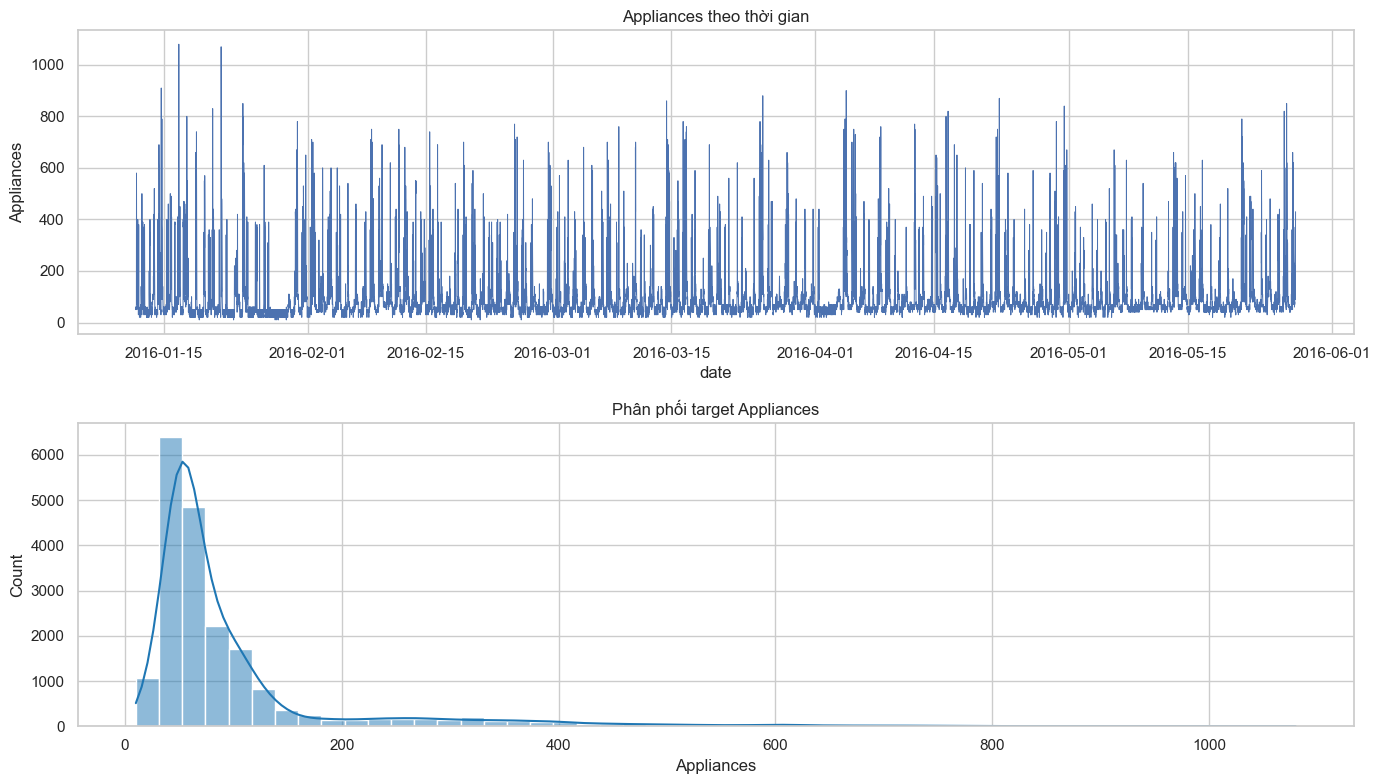

,autocorrelation
lag_1,0.753166
lag_6,0.323661
lag_144,0.216741


,count,mean,std,min,25%,50%,75%,max
Appliances,19735.0,97.694958,102.524891,10.000000,50.000000,60.000000,100.000000,1080.000000
lights,19735.0,3.801875,7.935988,0.000000,0.000000,0.000000,0.000000,70.000000
T1,19735.0,21.686571,1.606066,16.790000,20.760000,21.600000,22.600000,26.260000
RH_1,19735.0,40.259739,3.979299,27.023333,37.333333,39.656667,43.066667,63.360000
T2,19735.0,20.341219,2.192974,16.100000,18.790000,20.000000,21.500000,29.856667
RH_2,19735.0,40.420420,4.069813,20.463333,37.900000,40.500000,43.260000,56.026667
T3,19735.0,22.267611,2.006111,17.200000,20.790000,22.100000,23.290000,29.236000
RH_3,19735.0,39.242500,3.254576,28.766667,36.900000,38.530000,41.760000,50.163333
T4,19735.0,20.855335,2.042884,15.100000,19.530000,20.666667,22.100000,26.200000
RH_4,19735.0,39.026904,4.341321,27.660000,35.530000,38.400000,42.156667,51.090000


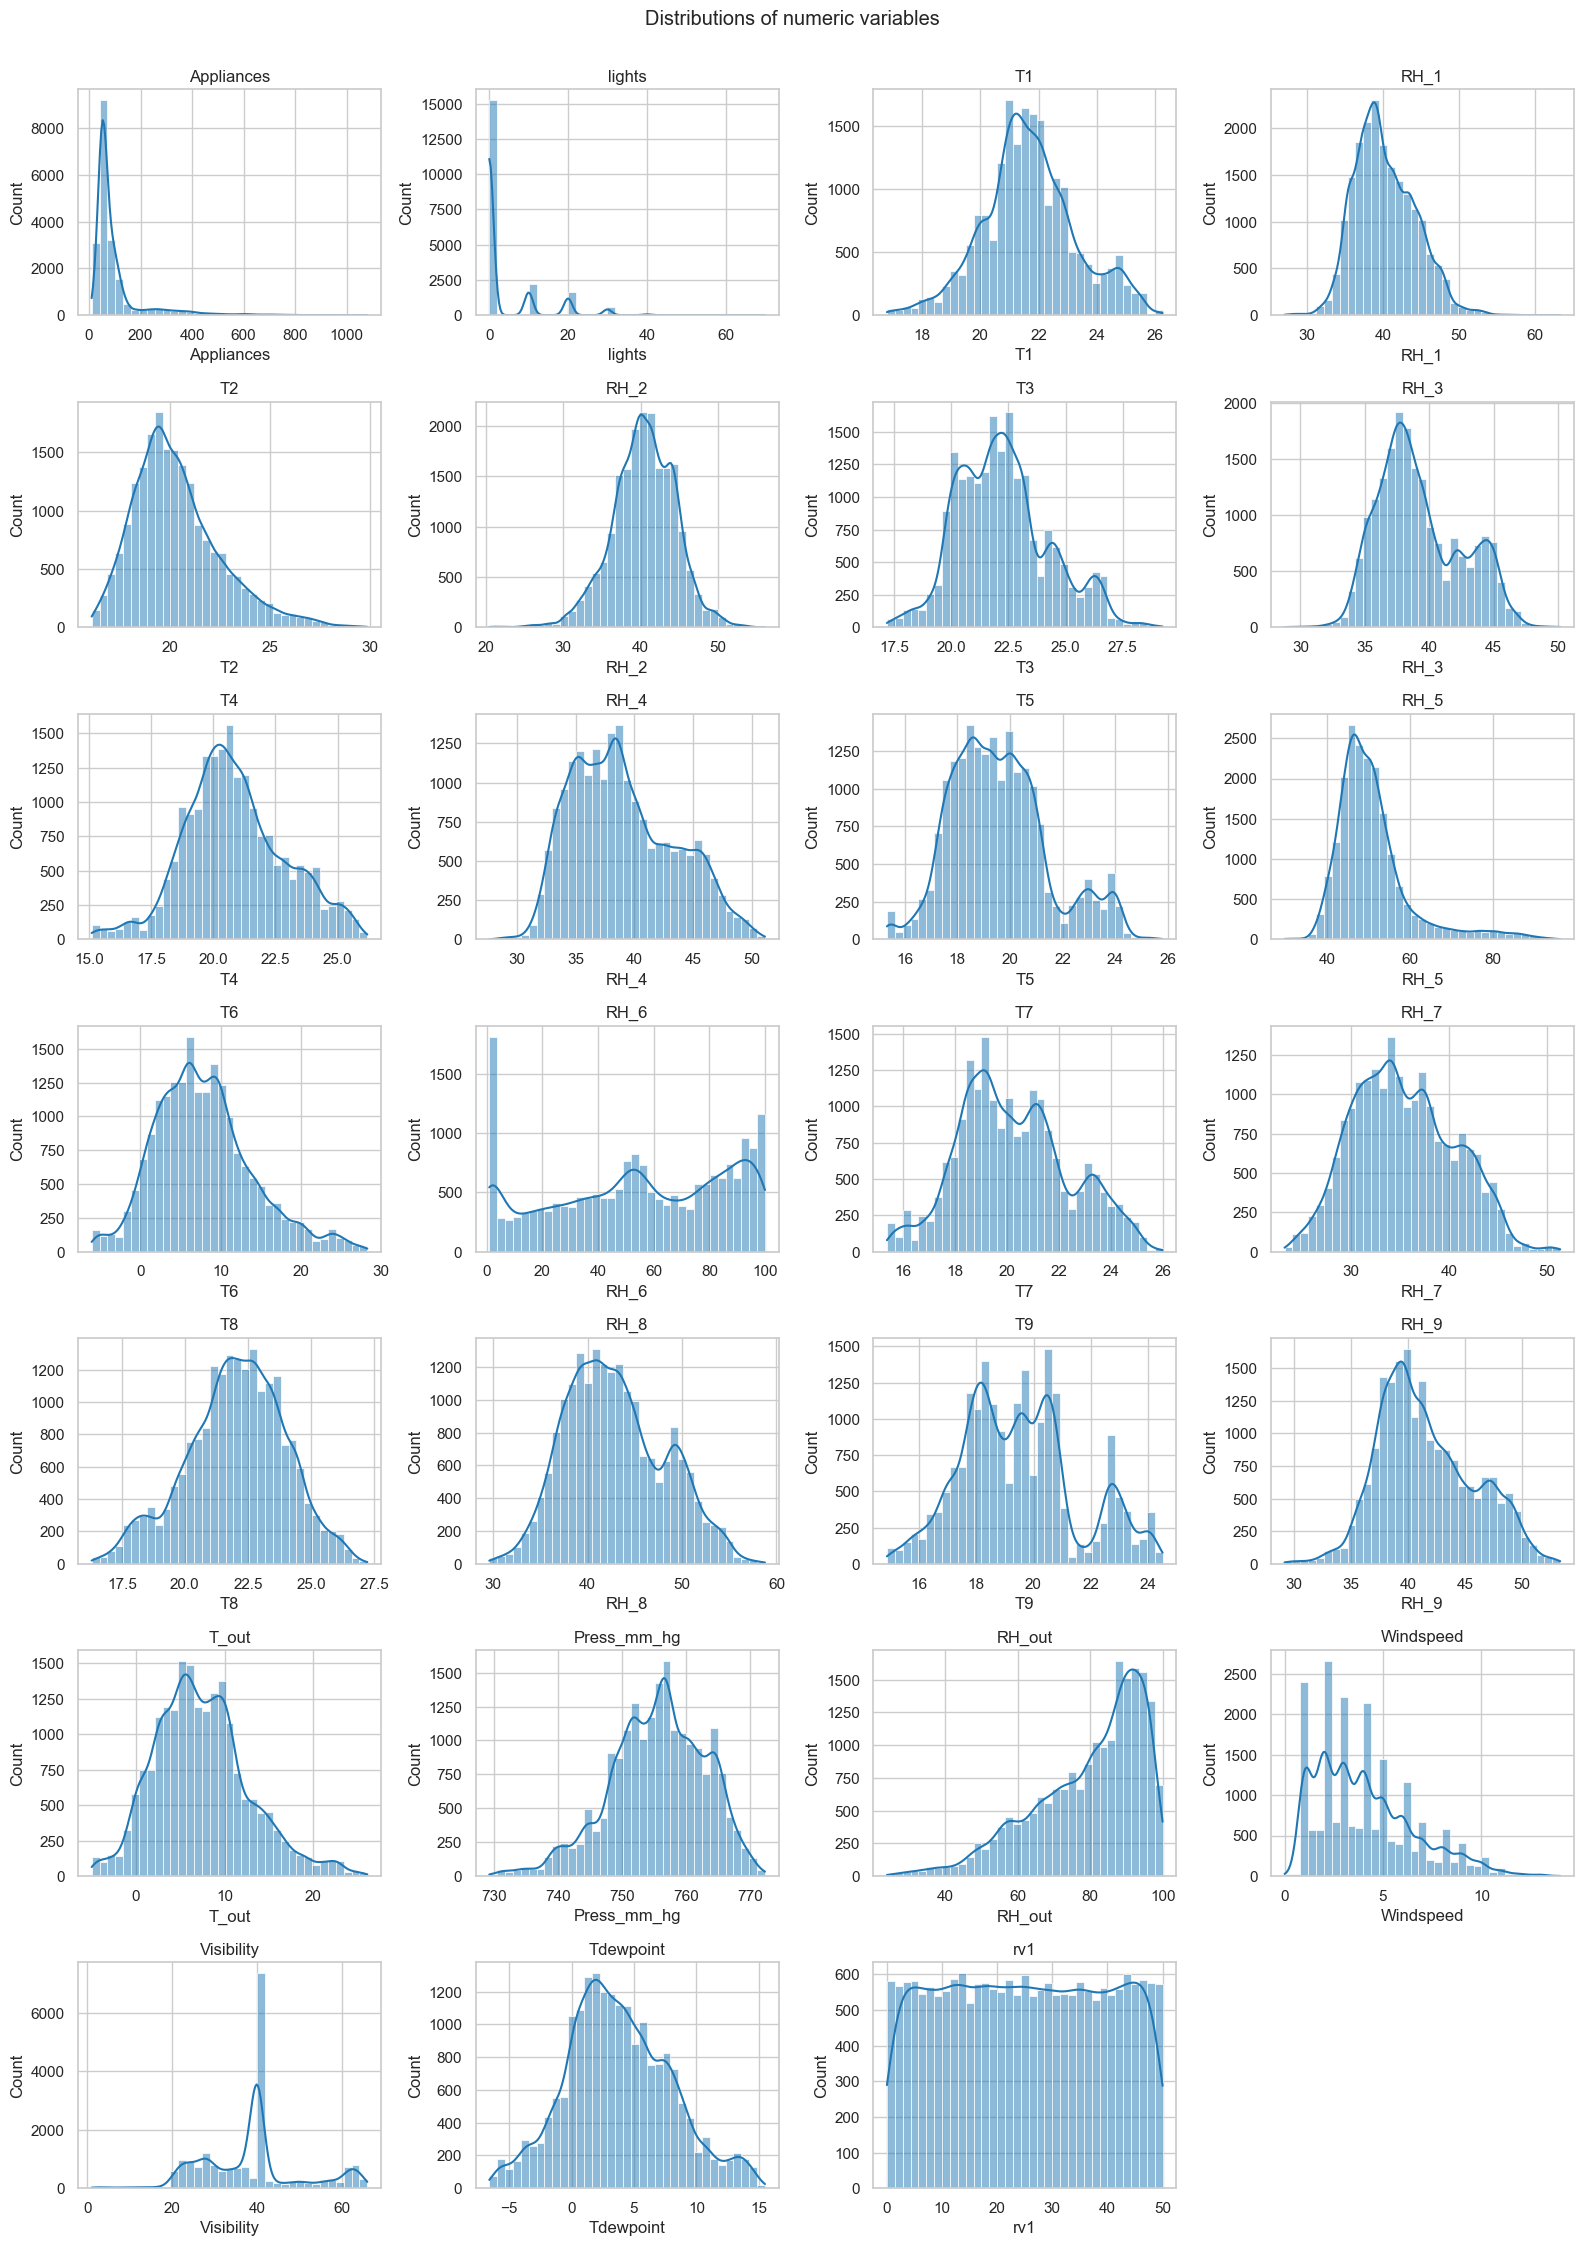

In [189]:
target_stats = df[TARGET_RAW].describe().to_frame("Appliances")
display(target_stats)

fig, axes = plt.subplots(2, 1, figsize=(14, 8))
axes[0].plot(df[TIME_COL], df[TARGET_RAW], linewidth=0.7)
axes[0].set_title("Appliances theo thời gian")
axes[0].set_xlabel("date")
axes[0].set_ylabel("Appliances")

sns.histplot(df[TARGET_RAW], bins=50, kde=True, color="tab:blue", ax=axes[1])
axes[1].set_title("Phân phối target Appliances")
plt.tight_layout()
plt.savefig(PATHS["figures"] / "target_overview.png", dpi=160, bbox_inches="tight")
plt.show()

lag_corr = pd.Series({
    "lag_1": df[TARGET_RAW].autocorr(1),
    "lag_6": df[TARGET_RAW].autocorr(6),
    "lag_144": df[TARGET_RAW].autocorr(144),
}, name="autocorrelation")
display(lag_corr.to_frame())

# Descriptive statistics and distribution of all numeric variables in the cleaned dataset.
numeric_eda_columns = df.select_dtypes(include=np.number).columns.tolist()
descriptive_statistics = df[numeric_eda_columns].describe().T
descriptive_statistics.to_csv(PATHS["reports"] / "descriptive_statistics_all_numeric.csv")
display(descriptive_statistics)

n_cols = 4
n_rows = int(np.ceil(len(numeric_eda_columns) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 3.2 * n_rows))
axes = np.asarray(axes).reshape(-1)
for ax, col in zip(axes, numeric_eda_columns):
    sns.histplot(df[col].dropna(), bins=35, kde=True, color="tab:blue", ax=ax)
    ax.set_title(col)
for ax in axes[len(numeric_eda_columns):]:
    ax.remove()
fig.suptitle("Distributions of numeric variables", y=1.002)
plt.tight_layout()
plt.savefig(PATHS["figures"] / "numeric_feature_distributions.png", dpi=160, bbox_inches="tight")
plt.show()

## 16. Time-series diagnostics for candidate features

Các candidate features được trực quan hóa theo thứ tự thời gian. Biểu đồ được chia thành các nhóm nhỏ để theo dõi xu hướng, dao động theo chu kỳ và thay đổi thang đo giữa các biến cảm biến.

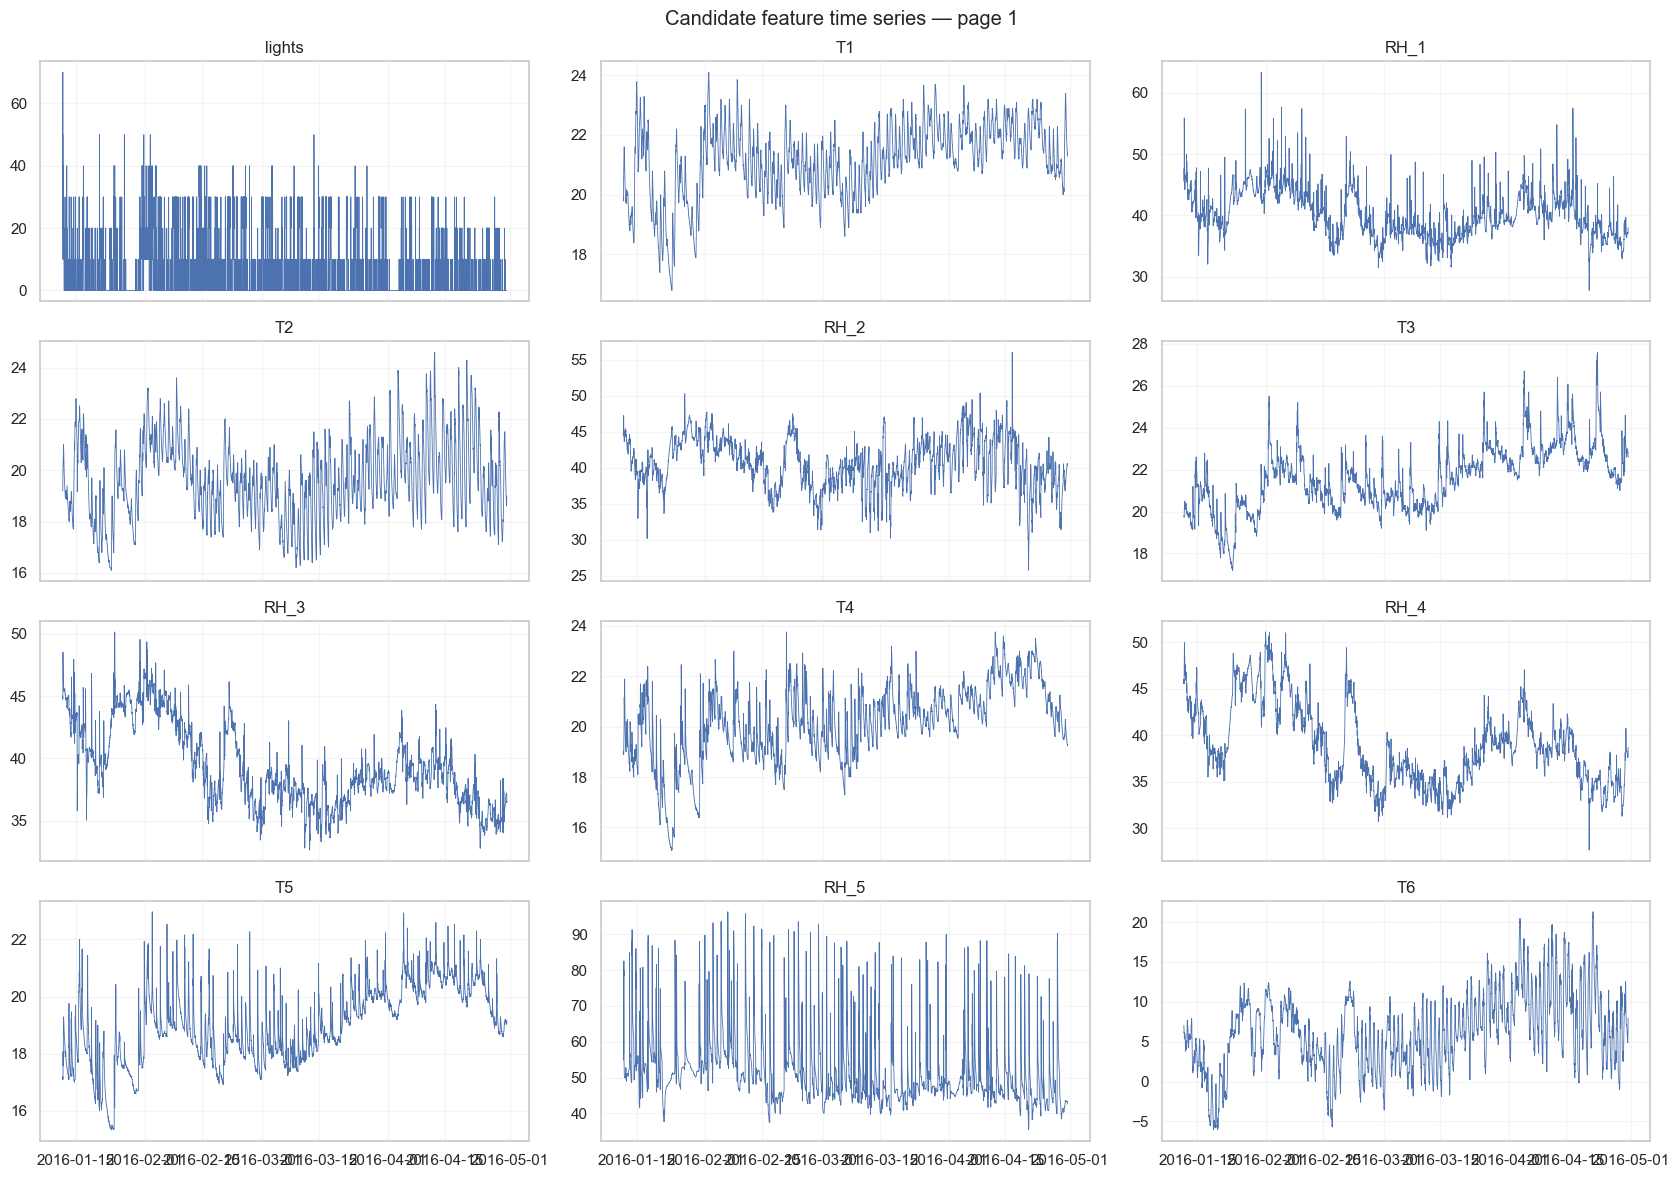

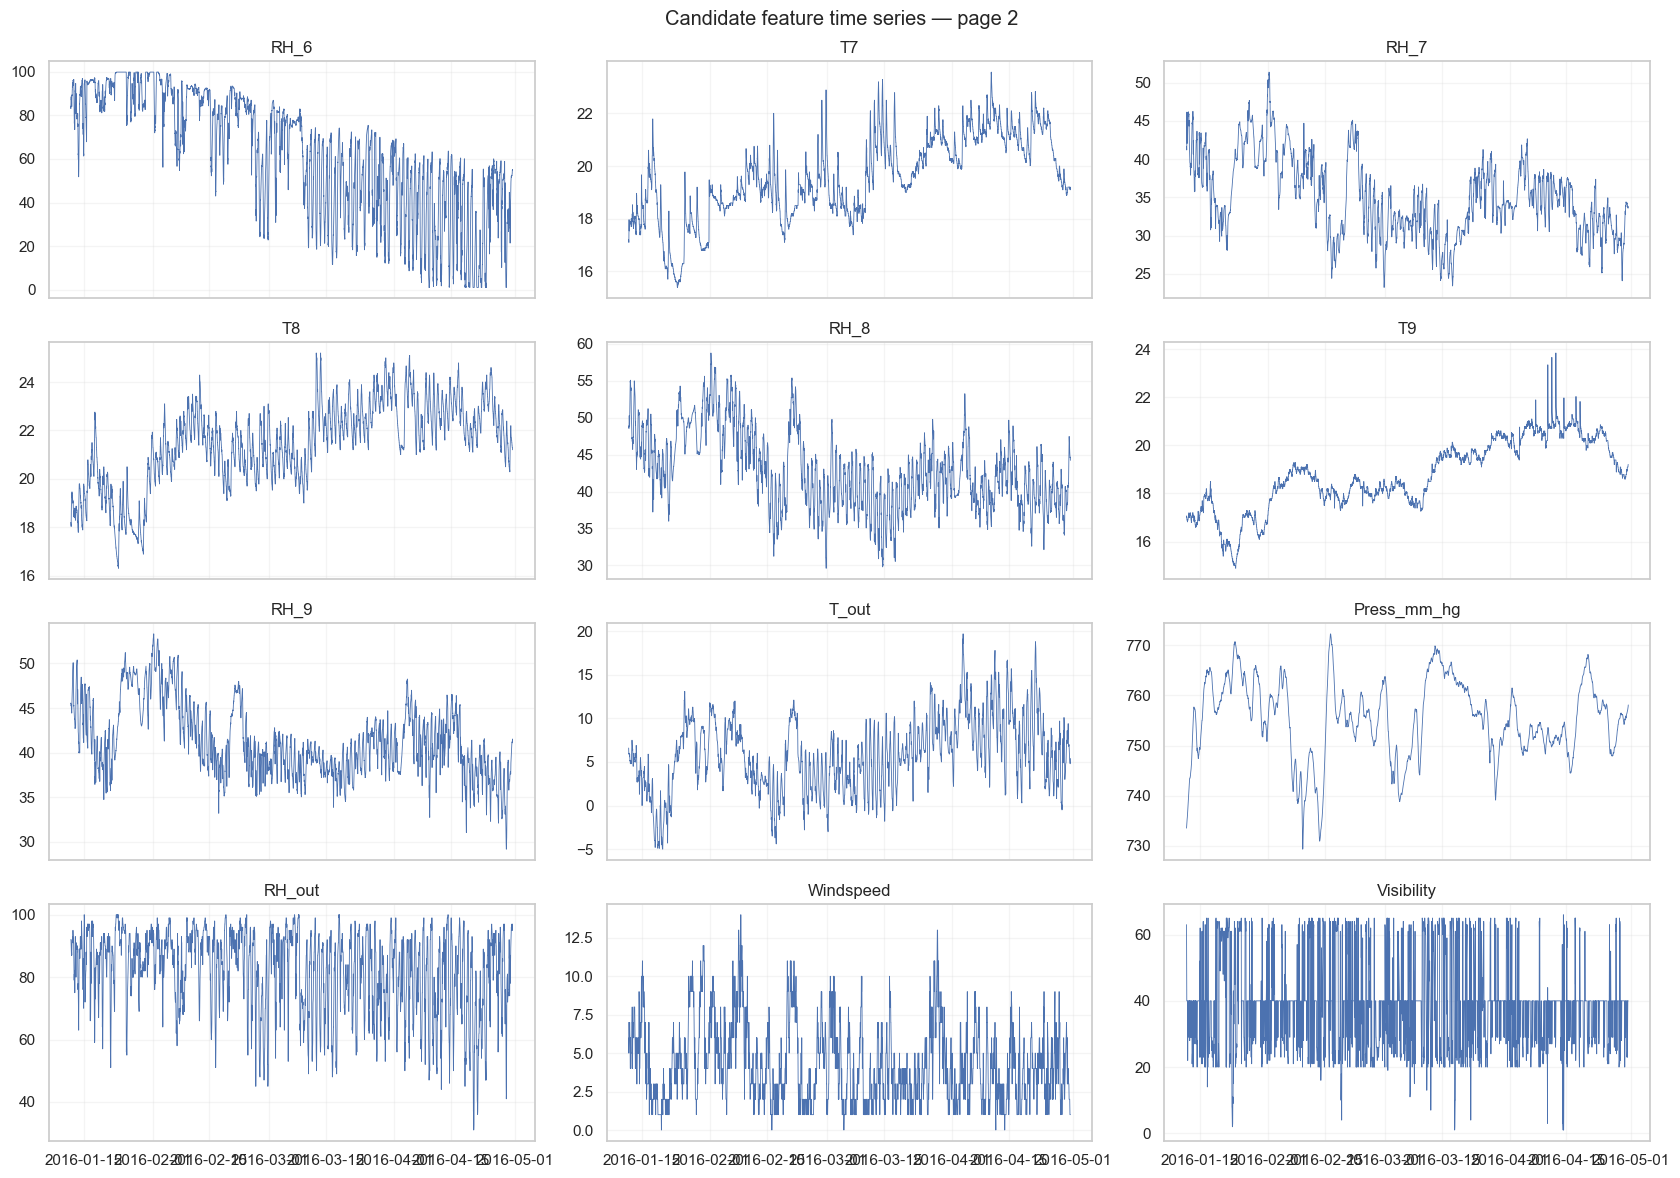

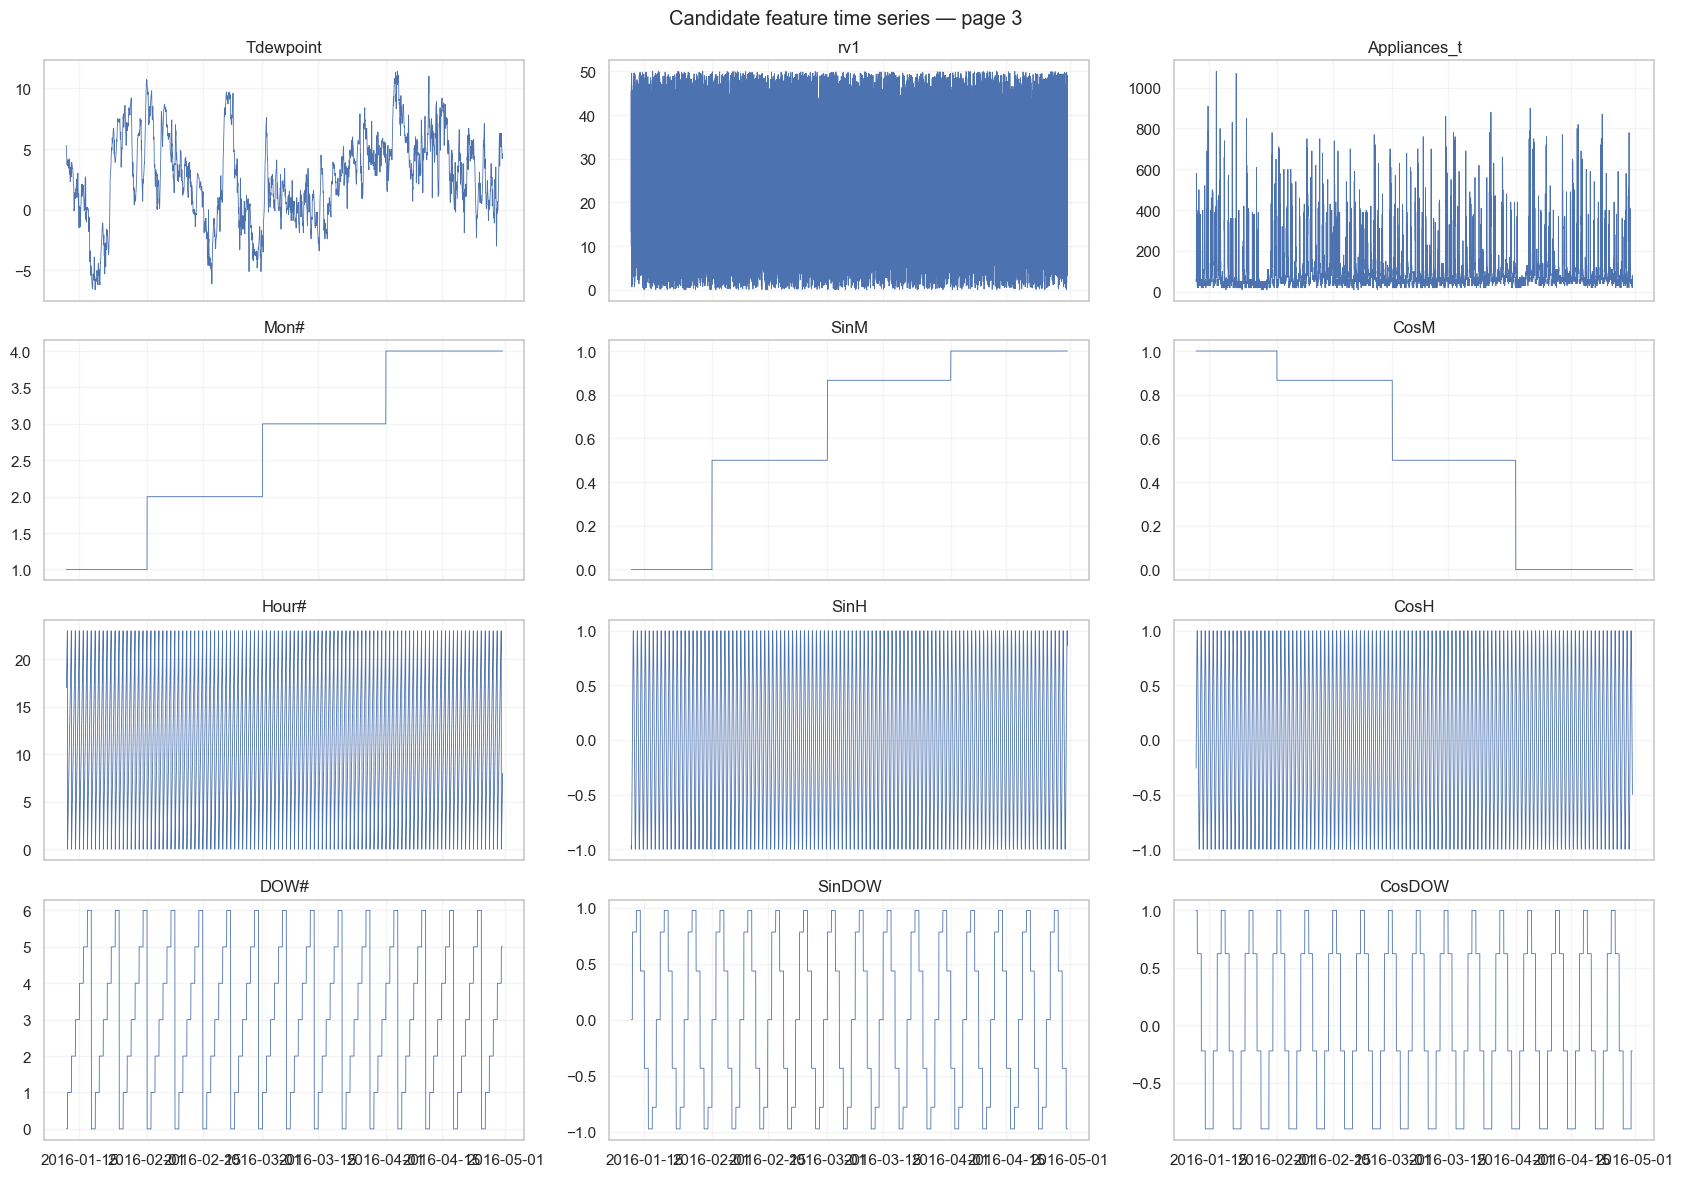

In [190]:
plot_columns = X_train_raw.columns.tolist()
features_per_page = 12
for page_start in range(0, len(plot_columns), features_per_page):
    page_features = plot_columns[page_start:page_start + features_per_page]
    ncols = 3
    nrows = int(np.ceil(len(page_features) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(17, 3.0 * nrows), sharex=True)
    axes = np.asarray(axes).reshape(-1)
    for ax, col in zip(axes, page_features):
        ax.plot(time_train, X_train_raw[col], linewidth=0.6)
        ax.set_title(col)
        ax.grid(alpha=0.2)
    for ax in axes[len(page_features):]:
        ax.remove()
    fig.suptitle(f"Candidate feature time series — page {page_start // features_per_page + 1}")
    plt.tight_layout()
    figure_file = PATHS["figures"] / f"candidate_features_timeseries_page_{page_start // features_per_page + 1}.png"
    plt.savefig(figure_file, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()

## 17. Pearson correlation và kiểm định hai phía

Bài báo sử dụng Pearson correlation với two-tailed test và ngưỡng ý nghĩa `α = 0.01`. Notebook tính hệ số tương quan và p-value trên training partition; heatmap hệ số và heatmap chỉ giữ các cặp đạt ngưỡng được xuất riêng. P-value trên chuỗi thời gian có tự tương quan cần được diễn giải thận trọng vì giả định độc lập của kiểm định Pearson cổ điển có thể không hoàn toàn thỏa mãn.

**Lưu ý suy luận:** Pearson two-tailed p-values được tính theo kiểm định chuẩn trên các cặp quan sát của training partition. Do chuỗi 10 phút có thể tự tương quan, các p-values này là mức ý nghĩa danh nghĩa; chúng không hiệu chỉnh effective sample size, multiple testing hoặc dependence theo thời gian. Hệ số Pearson được dùng cho mô tả liên hệ tuyến tính, không được diễn giải thành quan hệ nhân quả.


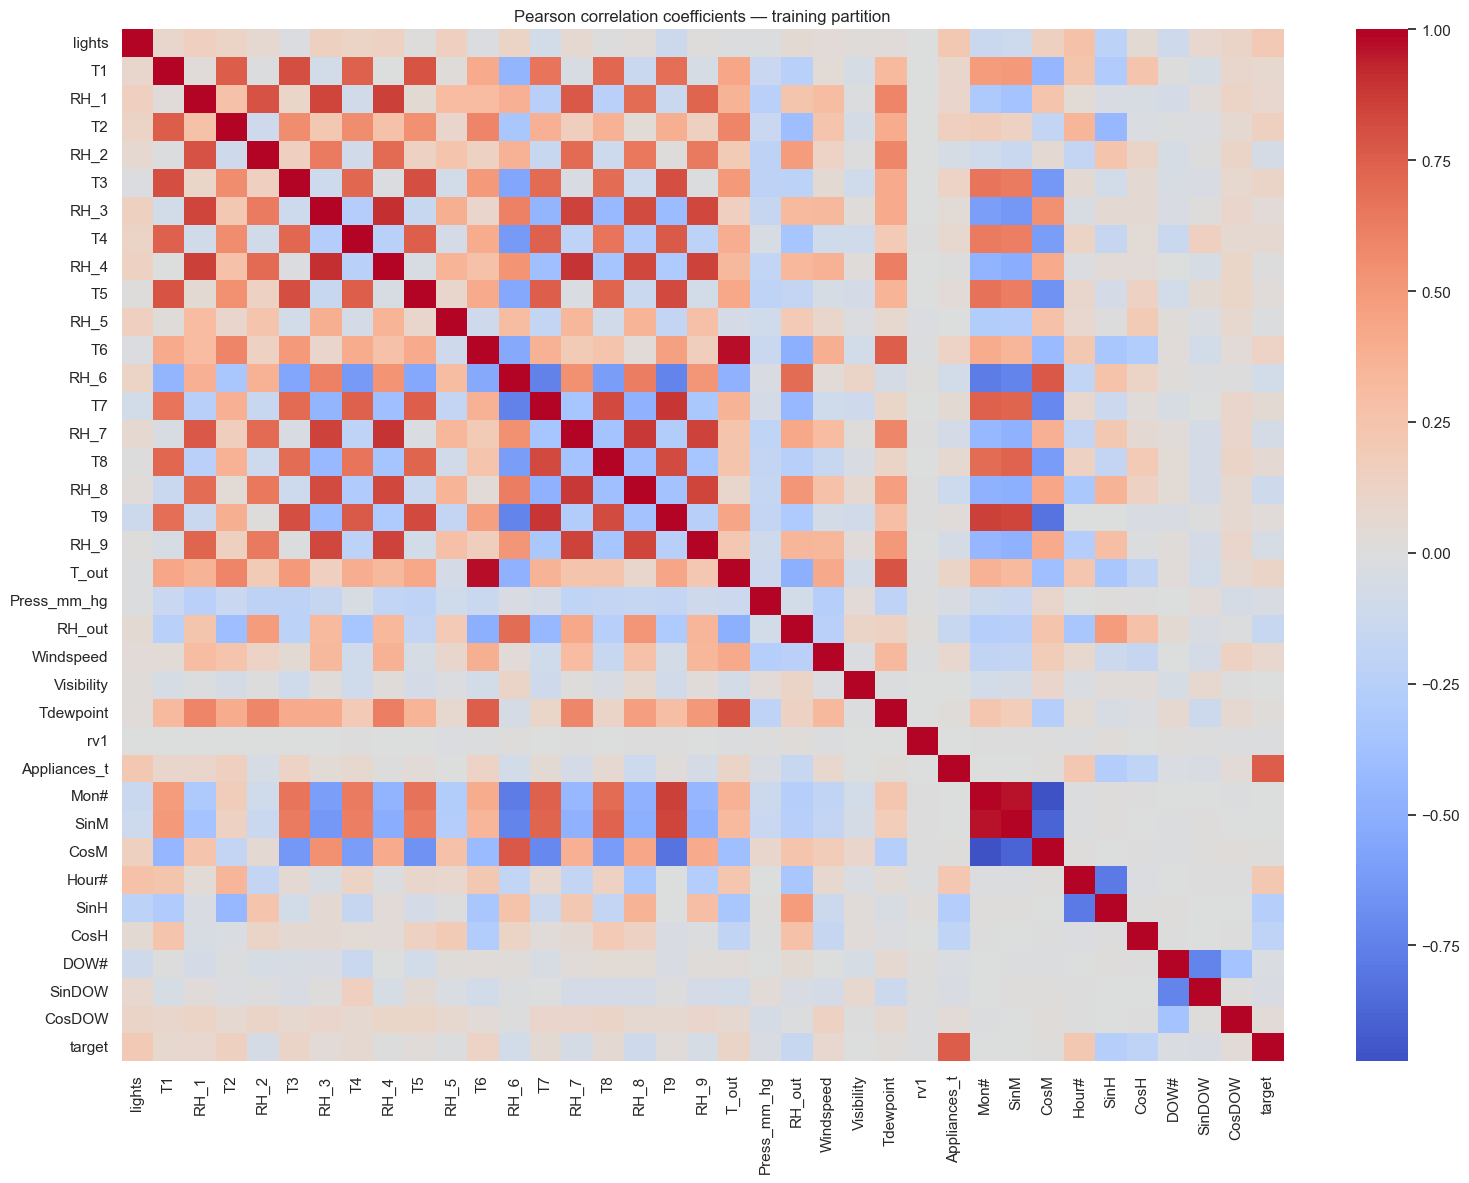

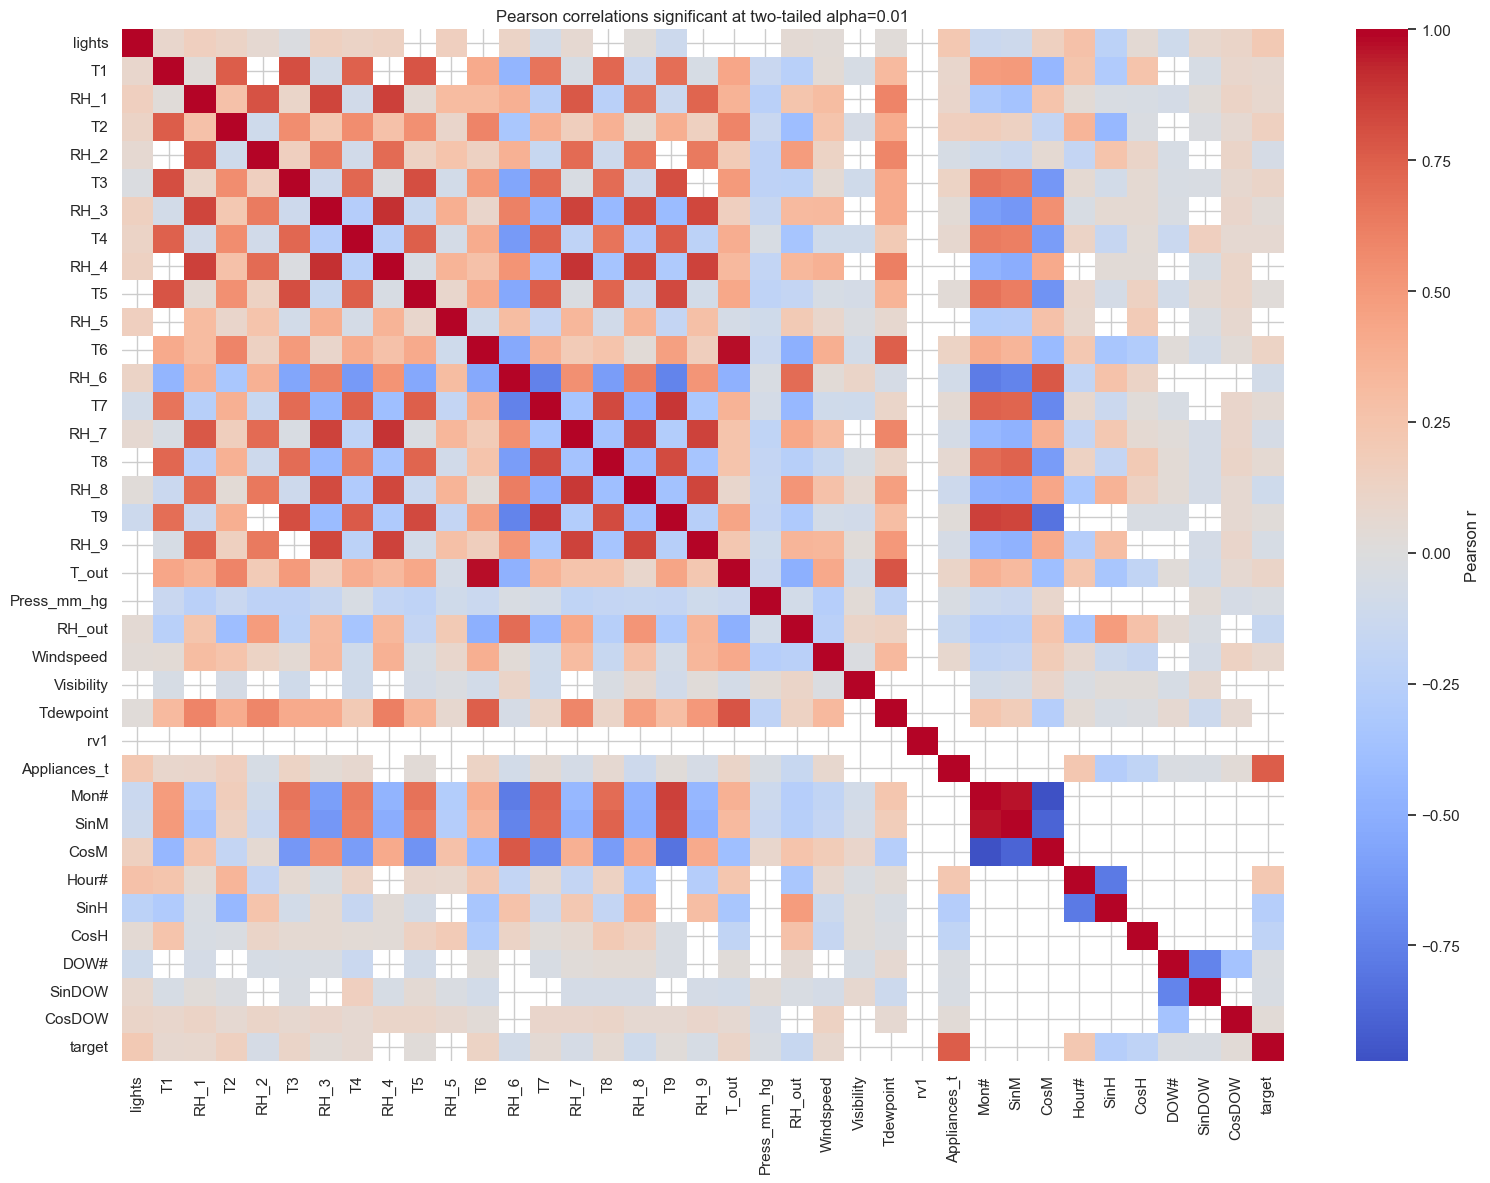

,pearson_r,p_value,significant_alpha_0_01
Appliances_t,0.756846,0.000000e+00,True
SinH,-0.260607,2.042642e-243,True
Hour#,0.215957,5.779733e-166,True
lights,0.208803,4.849451e-155,True
CosH,-0.208112,5.233811e-154,True
RH_out,-0.151117,2.748885e-81,True
T2,0.147582,1.417599e-77,True
T6,0.124178,2.755374e-55,True
T3,0.111499,7.473387e-45,True
RH_8,-0.108275,2.209170e-42,True


In [191]:
from scipy.stats import pearsonr

train_for_corr = X_train.copy()
train_for_corr["target"] = y_train.to_numpy()
corr_matrix = train_for_corr.corr(method="pearson")

corr_pvalues = pd.DataFrame(np.ones(corr_matrix.shape), index=corr_matrix.index, columns=corr_matrix.columns)
for i, col_i in enumerate(train_for_corr.columns):
    for col_j in train_for_corr.columns[i + 1:]:
        x = train_for_corr[col_i].to_numpy(dtype=float)
        y = train_for_corr[col_j].to_numpy(dtype=float)
        valid = np.isfinite(x) & np.isfinite(y)
        if valid.sum() >= 3 and np.nanstd(x[valid]) > 0 and np.nanstd(y[valid]) > 0:
            _, p_value = pearsonr(x[valid], y[valid])
        else:
            p_value = np.nan
        corr_pvalues.loc[col_i, col_j] = p_value
        corr_pvalues.loc[col_j, col_i] = p_value
np.fill_diagonal(corr_pvalues.values, 0.0)

ALPHA_PEARSON = 0.01
corr_significance = corr_pvalues < ALPHA_PEARSON
corr_matrix.to_csv(PATHS["reports"] / "pearson_correlation_coefficients.csv")
corr_pvalues.to_csv(PATHS["reports"] / "pearson_correlation_pvalues.csv")
corr_significance.to_csv(PATHS["reports"] / "pearson_significance_alpha_0_01.csv")

plt.figure(figsize=(16, 12))
sns.heatmap(corr_matrix, cmap="coolwarm", center=0, annot=False, square=False)
plt.title("Pearson correlation coefficients — training partition")
plt.tight_layout()
plt.savefig(PATHS["figures"] / "pearson_correlation_train.png", dpi=160, bbox_inches="tight")
plt.show()

nonsignificant_mask = corr_pvalues >= ALPHA_PEARSON
plt.figure(figsize=(16, 12))
sns.heatmap(corr_matrix, mask=nonsignificant_mask, cmap="coolwarm", center=0,
            annot=False, square=False, cbar_kws={"label": "Pearson r"})
plt.title(f"Pearson correlations significant at two-tailed alpha={ALPHA_PEARSON}")
plt.tight_layout()
plt.savefig(PATHS["figures"] / "pearson_significant_only_alpha_0_01.png", dpi=160, bbox_inches="tight")
plt.show()

corr_with_target = corr_matrix["target"].drop("target").sort_values(key=lambda x: x.abs(), ascending=False)
target_corr_table = pd.DataFrame({
    "pearson_r": corr_with_target,
    "p_value": corr_pvalues.loc[corr_with_target.index, "target"],
})
target_corr_table["significant_alpha_0_01"] = target_corr_table["p_value"] < ALPHA_PEARSON
display(target_corr_table)
target_corr_table.to_csv(PATHS["reports"] / "pearson_corr_with_target.csv")

## Giai đoạn C — Tối ưu hyperparameters, dự báo và diễn giải

Giai đoạn C gồm `Bayesian Optimization`, huấn luyện năm ML models trên `S0`, `S1`, `S2`, `S1S2`, các baseline đối chứng, đánh giá trên holdout test, trực quan hóa và `SHAP`. `quick` là smoke test; các kết quả nghiên cứu chính thức được lưu trong `outputs/paper/`.


## 18. Bayesian Optimization

`Bayesian Optimization` được sử dụng để lựa chọn hyperparameters trong training partition. `TimeSeriesSplit` duy trì thứ tự thời gian trong các validation folds. Trong `quick`, bước tối ưu được bỏ qua; trong `paper`, cấu hình được tìm kiếm bằng `BayesSearchCV`. Đây là bản triển khai Python thay thế cho MATLAB Statistics and Machine Learning Toolbox.

In [192]:
RUN_BAYES_OPTIMIZATION = (EXPERIMENT_MODE == "paper")


def run_bayesian_optimization(X, y, initial_models):
    try:
        from skopt import BayesSearchCV
        from skopt.space import Real, Integer
    except Exception as exc:
        raise ImportError("Không import được scikit-optimize. Hãy chạy lại cell cài thư viện.") from exc

    search_spaces = {
        "LASSO": {"alpha": Real(1e-6, 1.0, prior="log-uniform")},
        "SVR-Linear": {
            "C": Real(0.1, 100.0, prior="log-uniform"),
            "epsilon": Real(1e-4, 0.1, prior="log-uniform"),
        },
        "SVR-RBF": {
            "C": Real(0.1, 100.0, prior="log-uniform"),
            "gamma": Real(1e-3, 100.0, prior="log-uniform"),
            "epsilon": Real(1e-4, 0.1, prior="log-uniform"),
        },
        "GPR": {
            "length_scale": Real(1e-3, 2.0, prior="log-uniform"),
            "alpha": Real(1e-5, 0.1, prior="log-uniform"),
        },
        "LSBoost": {
            "n_estimators": Integer(30, 250),
            "learning_rate": Real(0.01, 0.3, prior="log-uniform"),
            "max_leaf_nodes": Integer(3, 32),
        },
    }

    if len(X) > BAYES_MAX_TRAIN_ROWS:
        opt_idx = np.linspace(0, len(X) - 1, BAYES_MAX_TRAIN_ROWS).astype(int)
        X_opt = X.iloc[opt_idx].copy()
        y_opt = np.asarray(y)[opt_idx]
    else:
        X_opt = X.copy()
        y_opt = np.asarray(y)

    cv = TimeSeriesSplit(n_splits=BAYES_CV_SPLITS)
    best_models, best_params, search_objects = {}, {}, {}
    for model_name, estimator in initial_models.items():
        print(f"Bayesian Optimization: {model_name}")
        cache_file = PATHS["checkpoints"] / f"bayes_search_{model_name.replace('-', '_')}.joblib"
        cache_meta_file = PATHS["checkpoints"] / f"bayes_search_{model_name.replace('-', '_')}.meta.json"
        expected_meta = {
            "model": model_name,
            "experiment_revision": EXPERIMENT_REVISION,
            "dataset_sha256": DATASET_SHA256,
            "n_iter": BAYES_ITERATIONS,
            "cv_splits": BAYES_CV_SPLITS,
            "train_rows_original": int(len(X)),
            "optimization_rows": int(len(X_opt)),
            "feature_names": list(X.columns),
            "random_state": RANDOM_SEED,
            "mode": EXPERIMENT_MODE,
            "search_spaces": {k: str(v) for k, v in search_spaces[model_name].items()},
        }
        search = None
        if cache_file.exists() and cache_meta_file.exists():
            try:
                stored_meta = json.loads(cache_meta_file.read_text(encoding="utf-8"))
                if stored_meta == expected_meta:
                    cached_search = joblib.load(cache_file)
                    if hasattr(cached_search, "best_estimator_"):
                        search = cached_search
                        print(" Loaded matching Bayesian Optimization checkpoint.")
            except Exception as exc:
                print(" Could not load Bayesian checkpoint; running search again:", repr(exc))
        if search is None:
            search = BayesSearchCV(
                estimator=estimator,
                search_spaces=search_spaces[model_name],
                n_iter=BAYES_ITERATIONS,
                scoring="neg_root_mean_squared_error",
                cv=cv,
                n_jobs=1,
                random_state=RANDOM_SEED,
                refit=True,
                error_score="raise",
            )
            search.fit(X_opt, y_opt)
            joblib.dump(search, cache_file)
            cache_meta_file.write_text(json.dumps(expected_meta, ensure_ascii=False, indent=2), encoding="utf-8")
        best_models[model_name] = search.best_estimator_
        best_params[model_name] = search.best_params_
        search_objects[model_name] = search
        print(" best score:", -search.best_score_, "best params:", search.best_params_)

    with open(PATHS["config"] / "bayesian_optimization_best_params.json", "w", encoding="utf-8") as f:
        json.dump(best_params, f, ensure_ascii=False, indent=2, default=str)
    return best_models, best_params, search_objects

if RUN_BAYES_OPTIMIZATION:
    paper_models, bayes_best_params, bayes_search_objects = run_bayesian_optimization(
        X_train, y_train, paper_models
    )
else:
    bayes_best_params = {name: "Table 3 reference configuration" for name in paper_models}
    bayes_search_objects = {}
    print("Reference hyperparameters retained; Bayesian Optimization skipped in quick mode.")

Bayesian Optimization: LASSO
 best score: 0.06240198666815533 best params: OrderedDict([('alpha', 0.00028881766539144715)])
Bayesian Optimization: SVR-Linear
 best score: 0.06306651436575954 best params: OrderedDict([('C', 36.36613831257664), ('epsilon', 0.0002657135426345108)])
Bayesian Optimization: SVR-RBF
 best score: 0.06402556505761718 best params: OrderedDict([('C', 43.16369668426757), ('epsilon', 0.015182724866877264), ('gamma', 0.0011268742703586286)])
Bayesian Optimization: GPR
 best score: 0.06908209101027378 best params: OrderedDict([('alpha', 0.1), ('length_scale', 2.0)])
Bayesian Optimization: LSBoost
 best score: 0.06542785284704698 best params: OrderedDict([('learning_rate', 0.01), ('max_leaf_nodes', 4), ('n_estimators', 250)])


## 19. Forecasting metrics và nguyên tắc đánh giá

Hiệu năng được đánh giá trên cùng chronological holdout test bằng `RMSE`, `MAE`, `MAPE`, `R²` và `rRMSE_article_literal`. `MAPE` loại các quan sát có target bằng 0 do phép chia không xác định; số quan sát bị loại được lưu kèm kết quả. `rRMSE_article_literal` giữ cách đọc trực tiếp công thức Eq. (21) được in trong bài báo. `NRMSE_mean_pct` và `sMAPE` là các chỉ số bổ sung, không thay thế metric gốc.

Các chỉ số được tính trên đơn vị đo gốc sau inverse transform. Holdout test không tham gia feature selection, Bayesian optimization hoặc model fitting.


In [193]:
def regression_metrics(y_true, y_pred):
    yt = np.asarray(y_true, dtype=float).ravel()
    yp = np.asarray(y_pred, dtype=float).ravel()
    rmse = float(np.sqrt(mean_squared_error(yt, yp)))
    mae = float(mean_absolute_error(yt, yp))
    nonzero = np.abs(yt) > 1e-12
    mape_pct = (
        float(np.mean(np.abs((yt[nonzero] - yp[nonzero]) / yt[nonzero])) * 100)
        if nonzero.any() else np.nan
    )
    r2 = float(r2_score(yt, yp)) if len(yt) > 1 else np.nan
    denom = float(np.sum(yp ** 2))
    rrmse_article_literal = (
        float(np.sqrt(mean_squared_error(yt, yp) / denom)) if denom > 0 else np.nan
    )
    nrmse_mean_pct = float(rmse / max(abs(np.mean(yt)), 1e-12) * 100)
    smape_denom = np.abs(yt) + np.abs(yp)
    smape_valid = smape_denom > 1e-12
    smape_pct = (
        float(np.mean(2 * np.abs(yt[smape_valid] - yp[smape_valid]) / smape_denom[smape_valid]) * 100)
        if smape_valid.any() else np.nan
    )
    return {
        "RMSE": rmse,
        "rRMSE_article_literal": rrmse_article_literal,
        "NRMSE_mean_pct_supplement": nrmse_mean_pct,
        "MAPE_pct_excluding_zero": mape_pct,
        "MAPE_excluded_zero_count": int((~nonzero).sum()),
        "sMAPE_pct_supplement": smape_pct,
        "MAE": mae,
        "R2": r2,
    }


def model_fit_predict(model, Xtr, ytr, Xte, model_name):
    return _fit_predict_safe(model, Xtr, ytr, Xte, model_name=model_name)

In [194]:
def model_fit_predict(model, Xtr, ytr, Xte, model_name):
    return _fit_predict_safe(model, Xtr, ytr, Xte, model_name=model_name)

feature_sets = {
    "S0": {name: feature_columns for name in paper_models},
    "S1": {name: S1 for name in paper_models},
    "S2": S2_by_model,
    "S1S2": S1S2_by_model,
}

result_rows = []
prediction_frames = []
fit_failures = []
running_metrics_path = PATHS["metrics"] / "paper_models_running_results.csv"
running_predictions_path = PATHS["metrics"] / "paper_models_predictions_running.parquet"

for subset_name, mapping in feature_sets.items():
    for model_name, estimator in paper_models.items():
        selected_features = list(mapping[model_name])
        Xtr = X_train[selected_features]
        Xte = X_test[selected_features]
        safe_model_name = model_name.replace("-", "_")
        model_file = PATHS["models"] / f"{subset_name}_{safe_model_name}.joblib"
        model_meta_file = PATHS["models"] / f"{subset_name}_{safe_model_name}.meta.json"
        expected_model_meta = {
            "experiment_revision": EXPERIMENT_REVISION,
            "experiment_mode": EXPERIMENT_MODE,
            "dataset_sha256": DATASET_SHA256,
            "feature_subset": subset_name,
            "model": model_name,
            "features": selected_features,
            "estimator_params": {k: repr(v) for k, v in estimator.get_params(deep=False).items()},
            "train_rows": int(len(Xtr)),
            "test_rows": int(len(Xte)),
            "random_seed": RANDOM_SEED,
        }

        print(f"Fitting {model_name} | {subset_name} | {len(selected_features)} features")
        try:
            fitted_model = None
            if model_file.exists() and model_meta_file.exists():
                try:
                    saved_meta = json.loads(model_meta_file.read_text(encoding="utf-8"))
                    if saved_meta == expected_model_meta:
                        saved_artifact = joblib.load(model_file)
                        fitted_model = saved_artifact["model"]
                        y_pred_scaled = fitted_model.predict(Xte)
                        print("  Reused matching fitted estimator checkpoint.")
                except Exception as cache_exc:
                    print("  Existing estimator could not be reused; refitting:", repr(cache_exc))
                    fitted_model = None

            if fitted_model is None:
                y_pred_scaled, fitted_model = model_fit_predict(
                    estimator, Xtr, y_train, Xte, model_name
                )
                joblib.dump({
                    "model": fitted_model,
                    "features": selected_features,
                    "scaler_y": scaler_y,
                    "feature_subset": subset_name,
                    "model_name": model_name,
                    "dataset_sha256": DATASET_SHA256,
                    "experiment_revision": EXPERIMENT_REVISION,
                }, model_file)
                model_meta_file.write_text(
                    json.dumps(expected_model_meta, ensure_ascii=False, indent=2),
                    encoding="utf-8"
                )

            y_pred = scaler_y.inverse_transform(
                np.asarray(y_pred_scaled).reshape(-1, 1)
            ).ravel()
            metrics = regression_metrics(y_test_raw, y_pred)
            row = {
                "feature_subset": subset_name,
                "model": model_name,
                "n_features": len(selected_features),
                "features": ", ".join(selected_features),
                "status": "ok",
                **metrics,
            }
            result_rows.append(row)

            pred_df = pd.DataFrame({
                "date": time_test.to_numpy(),
                "y_true": y_test_raw.to_numpy(),
                "y_pred": y_pred,
                "residual": y_test_raw.to_numpy() - y_pred,
                "feature_subset": subset_name,
                "model": model_name,
            })
            prediction_frames.append(pred_df)

        except Exception as exc:
            fit_failures.append({
                "feature_subset": subset_name,
                "model": model_name,
                "error": repr(exc),
            })
            print(f"FAILED {subset_name}/{model_name}: {exc!r}")

        # Incremental writes preserve completed work if the process is interrupted.
        pd.DataFrame(result_rows).to_csv(running_metrics_path, index=False)
        if prediction_frames:
            pd.concat(prediction_frames, ignore_index=True).to_parquet(
                running_predictions_path, index=False
            )
        if fit_failures:
            pd.DataFrame(fit_failures).to_csv(
                PATHS["reports"] / "paper_model_fit_failures.csv", index=False
            )

paper_results = pd.DataFrame(result_rows)
if paper_results.empty:
    raise RuntimeError("Không có paper model nào fit thành công; xem paper_model_fit_failures.csv.")
predictions_all = (
    pd.concat(prediction_frames, ignore_index=True)
    if prediction_frames else pd.DataFrame()
)
paper_results.to_csv(PATHS["metrics"] / "paper_models_results.csv", index=False)
predictions_all.to_parquet(
    PATHS["metrics"] / "paper_models_predictions.parquet", index=False
)
if fit_failures:
    pd.DataFrame(fit_failures).to_csv(
        PATHS["reports"] / "paper_model_fit_failures.csv", index=False
    )

display(paper_results.sort_values(["RMSE", "MAE"]).reset_index(drop=True))


Fitting LASSO | S0 | 36 features
Fitting SVR-Linear | S0 | 36 features
Fitting SVR-RBF | S0 | 36 features
Fitting GPR | S0 | 36 features
Fitting LSBoost | S0 | 36 features
Fitting LASSO | S1 | 10 features
Fitting SVR-Linear | S1 | 10 features
Fitting SVR-RBF | S1 | 10 features
Fitting GPR | S1 | 10 features
Fitting LSBoost | S1 | 10 features
Fitting LASSO | S2 | 1 features
Fitting SVR-Linear | S2 | 1 features
Fitting SVR-RBF | S2 | 1 features
Fitting GPR | S2 | 1 features
Fitting LSBoost | S2 | 1 features
Fitting LASSO | S1S2 | 1 features
Fitting SVR-Linear | S1S2 | 1 features
Fitting SVR-RBF | S1S2 | 1 features
Fitting GPR | S1S2 | 1 features
Fitting LSBoost | S1S2 | 1 features


,feature_subset,model,n_features,features,status,RMSE,rRMSE_article_literal,NRMSE_mean_pct_supplement,MAPE_pct_excluding_zero,MAPE_excluded_zero_count,sMAPE_pct_supplement,MAE,R2
0,S1,LSBoost,10,"Appliances_t, RH_3, lights, SinH, T2, rv1, Hou...",ok,61.223997,0.008350,63.525530,24.249230,0,21.392815,26.543855,0.547735
1,S0,LSBoost,36,"lights, T1, RH_1, T2, RH_2, T3, RH_3, T4, RH_4...",ok,61.274424,0.008382,63.577853,24.221617,0,21.381851,26.524782,0.546990
2,S0,LASSO,36,"lights, T1, RH_1, T2, RH_2, T3, RH_3, T4, RH_4...",ok,61.280461,0.008247,63.584117,25.877943,0,22.867552,27.384938,0.546901
3,S2,LSBoost,1,Appliances_t,ok,61.297607,0.008370,63.601907,24.505619,0,21.640793,26.693146,0.546647
4,S1S2,LSBoost,1,Appliances_t,ok,61.297607,0.008370,63.601907,24.505619,0,21.640793,26.693146,0.546647
5,S1,LASSO,10,"Appliances_t, RH_3, lights, SinH, T2, rv1, Hou...",ok,61.320689,0.008330,63.625857,24.966151,0,22.316552,26.929178,0.546305
6,S1,GPR,10,"Appliances_t, RH_3, lights, SinH, T2, rv1, Hou...",ok,61.575189,0.008397,63.889924,25.221129,0,22.882299,27.337066,0.542532
7,S1,SVR-RBF,10,"Appliances_t, RH_3, lights, SinH, T2, rv1, Hou...",ok,61.587307,0.008595,63.902497,21.494474,0,20.114934,25.240089,0.542352
8,S2,GPR,1,Appliances_t,ok,61.642860,0.008341,63.960139,25.432188,0,22.529832,26.880983,0.541526
9,S1S2,GPR,1,Appliances_t,ok,61.642860,0.008341,63.960139,25.432188,0,22.529832,26.880983,0.541526


## 20. Baseline models trên cùng holdout test

Các baseline gồm `Persistence`, `Ridge`, `RandomForest` và `HistGradientBoosting`. `Persistence` sử dụng `Appliances_t` làm dự báo one-step-ahead; các baseline còn lại sử dụng toàn bộ `S0` candidate features. Các phương pháp này là đối chứng bổ sung, không thuộc năm model và ba Feature Selection tracks được đánh giá trong bài báo.

In [195]:
baseline_estimators = {
    "Ridge": Ridge(alpha=1.0),
    "RandomForest": RandomForestRegressor(n_estimators=350, min_samples_leaf=2,
                                          random_state=RANDOM_SEED, n_jobs=-1),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=250, learning_rate=0.06,
                                                           max_leaf_nodes=31, random_state=RANDOM_SEED),
}

baseline_rows = []
baseline_predictions = []

# Persistence baseline.
y_pred_persistence = X_test_raw["Appliances_t"].to_numpy(dtype=float)
metrics = regression_metrics(y_test_raw, y_pred_persistence)
baseline_rows.append({"feature_subset": "S0", "model": "Persistence", "n_features": 1,
                      "features": "Appliances_t", **metrics})
baseline_predictions.append(pd.DataFrame({
    "date": time_test.to_numpy(), "y_true": y_test_raw.to_numpy(),
    "y_pred": y_pred_persistence, "residual": y_test_raw.to_numpy() - y_pred_persistence,
    "feature_subset": "S0", "model": "Persistence"
}))

for model_name, estimator in baseline_estimators.items():
    print("Fitting baseline:", model_name)
    fitted = clone(estimator).fit(X_train, y_train)
    pred_scaled = fitted.predict(X_test)
    pred = scaler_y.inverse_transform(np.asarray(pred_scaled).reshape(-1, 1)).ravel()
    metrics = regression_metrics(y_test_raw, pred)
    baseline_rows.append({"feature_subset": "S0", "model": model_name, "n_features": len(feature_columns),
                          "features": ", ".join(feature_columns), **metrics})
    baseline_predictions.append(pd.DataFrame({
        "date": time_test.to_numpy(), "y_true": y_test_raw.to_numpy(),
        "y_pred": pred, "residual": y_test_raw.to_numpy() - pred,
        "feature_subset": "S0", "model": model_name
    }))
    joblib.dump(fitted, PATHS["models"] / f"baseline_{model_name}.joblib")

baseline_results = pd.DataFrame(baseline_rows)
baseline_predictions_all = pd.concat(baseline_predictions, ignore_index=True)
baseline_results.to_csv(PATHS["metrics"] / "baseline_results.csv", index=False)
baseline_predictions_all.to_parquet(PATHS["metrics"] / "baseline_predictions.parquet", index=False)

display(baseline_results.sort_values("RMSE"))

Fitting baseline: Ridge
Fitting baseline: RandomForest
Fitting baseline: HistGradientBoosting


,feature_subset,model,n_features,features,RMSE,rRMSE_article_literal,NRMSE_mean_pct_supplement,MAPE_pct_excluding_zero,MAPE_excluded_zero_count,sMAPE_pct_supplement,MAE,R2
1,S0,Ridge,36,"lights, T1, RH_1, T2, RH_2, T3, RH_3, T4, RH_4...",61.393249,0.008545,63.701144,23.143621,0,21.840983,26.333199,0.545231
3,S0,HistGradientBoosting,36,"lights, T1, RH_1, T2, RH_2, T3, RH_3, T4, RH_4...",64.144688,0.007739,66.556015,34.228321,0,27.487464,33.990690,0.503555
0,S0,Persistence,1,Appliances_t,66.437640,0.007982,68.935164,21.936115,0,20.056003,26.650621,0.467429
2,S0,RandomForest,36,"lights, T1, RH_1, T2, RH_2, T3, RH_3, T4, RH_4...",97.809147,0.008698,101.485989,72.555550,0,44.985272,65.064723,-0.154273


## 21. Tổng hợp metrics và xác định best configuration

`Table 7`-style summary tổng hợp hiệu suất của 15 cấu hình thuộc ba nhánh Feature Selection. `S0` và các baseline được giữ thành nhóm đối chứng bổ sung. Xếp hạng best configuration sử dụng RMSE trên cùng holdout test; MAE và R² được dùng làm chỉ số bổ trợ.

In [196]:
all_results = pd.concat([paper_results, baseline_results], ignore_index=True)
all_results = all_results.sort_values(["RMSE", "MAE"], ascending=True).reset_index(drop=True)
all_results.to_csv(PATHS["metrics"] / "all_models_comparison.csv", index=False)

paper_avg = paper_results.groupby("feature_subset")[
    ["RMSE", "MAE", "MAPE_pct_excluding_zero", "R2", "n_features"]
].mean().sort_values("RMSE")
print("Average performance by paper feature subset:")
display(paper_avg)
paper_avg.to_csv(PATHS["reports"] / "average_performance_by_feature_subset.csv")

print("Overall top 10:")
display(all_results.head(10))

# Table 7 analogue: one row per model and feature-selection track.
table7_analogue = paper_results[[
    "feature_subset", "model", "n_features", "RMSE", "rRMSE_article_literal",
    "MAPE_pct_excluding_zero", "MAE", "R2"
]].copy()
table7_analogue.to_csv(PATHS["reports"] / "table7_model_performance.csv", index=False)

best_row = all_results.iloc[0].to_dict()
with open(PATHS["reports"] / "best_model_summary.json", "w", encoding="utf-8") as f:
    json.dump(best_row, f, ensure_ascii=False, indent=2, default=str)
print("Best configuration:", best_row["feature_subset"], best_row["model"])

Average performance by paper feature subset:


,RMSE,MAE,MAPE_pct_excluding_zero,R2,n_features
feature_subset,,,,,
S1,61.558700,26.224907,23.382179,0.542766,10.0
S1S2,61.952516,26.298261,23.584700,0.536877,1.0
S2,61.952516,26.298261,23.584700,0.536877,1.0
S0,63.111617,29.012166,27.583230,0.518369,36.0


Overall top 10:


,feature_subset,model,n_features,features,status,RMSE,rRMSE_article_literal,NRMSE_mean_pct_supplement,MAPE_pct_excluding_zero,MAPE_excluded_zero_count,sMAPE_pct_supplement,MAE,R2
0,S1,LSBoost,10,"Appliances_t, RH_3, lights, SinH, T2, rv1, Hou...",ok,61.223997,0.008350,63.525530,24.249230,0,21.392815,26.543855,0.547735
1,S0,LSBoost,36,"lights, T1, RH_1, T2, RH_2, T3, RH_3, T4, RH_4...",ok,61.274424,0.008382,63.577853,24.221617,0,21.381851,26.524782,0.546990
2,S0,LASSO,36,"lights, T1, RH_1, T2, RH_2, T3, RH_3, T4, RH_4...",ok,61.280461,0.008247,63.584117,25.877943,0,22.867552,27.384938,0.546901
3,S2,LSBoost,1,Appliances_t,ok,61.297607,0.008370,63.601907,24.505619,0,21.640793,26.693146,0.546647
4,S1S2,LSBoost,1,Appliances_t,ok,61.297607,0.008370,63.601907,24.505619,0,21.640793,26.693146,0.546647
5,S1,LASSO,10,"Appliances_t, RH_3, lights, SinH, T2, rv1, Hou...",ok,61.320689,0.008330,63.625857,24.966151,0,22.316552,26.929178,0.546305
6,S0,Ridge,36,"lights, T1, RH_1, T2, RH_2, T3, RH_3, T4, RH_4...",NaN,61.393249,0.008545,63.701144,23.143621,0,21.840983,26.333199,0.545231
7,S1,GPR,10,"Appliances_t, RH_3, lights, SinH, T2, rv1, Hou...",ok,61.575189,0.008397,63.889924,25.221129,0,22.882299,27.337066,0.542532
8,S1,SVR-RBF,10,"Appliances_t, RH_3, lights, SinH, T2, rv1, Hou...",ok,61.587307,0.008595,63.902497,21.494474,0,20.114934,25.240089,0.542352
9,S2,GPR,1,Appliances_t,ok,61.642860,0.008341,63.960139,25.432188,0,22.529832,26.880983,0.541526


Best configuration: S1 LSBoost


## 22. Trực quan hóa kết quả và kiểm tra sai số

Các biểu đồ được lưu trong thư mục figures của lần chạy hiện tại. Phân tích tập trung vào model nào có RMSE/MAE tốt, có hiện tượng lệch có hệ thống hay không, và Feature Selection có giảm số lượng features mà vẫn giữ hiệu năng hay không.

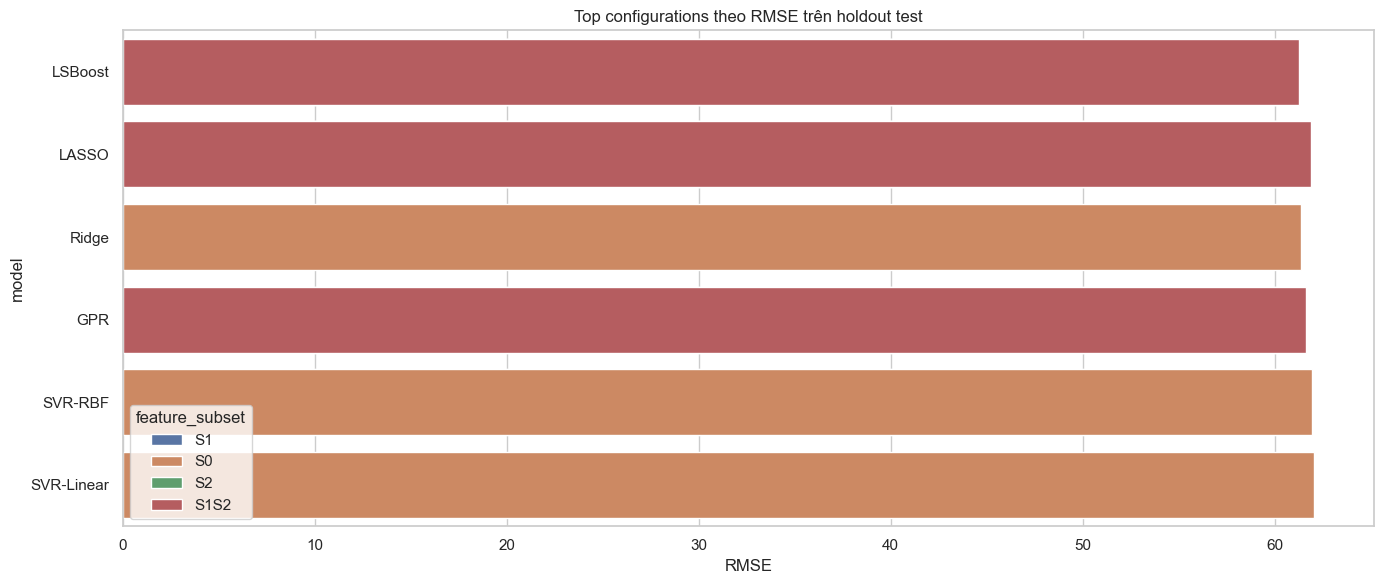

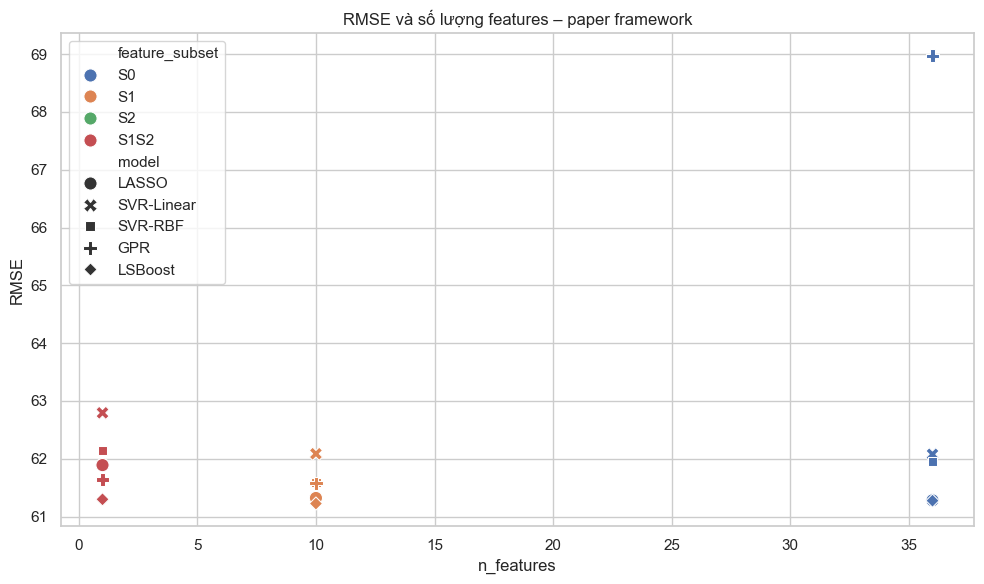

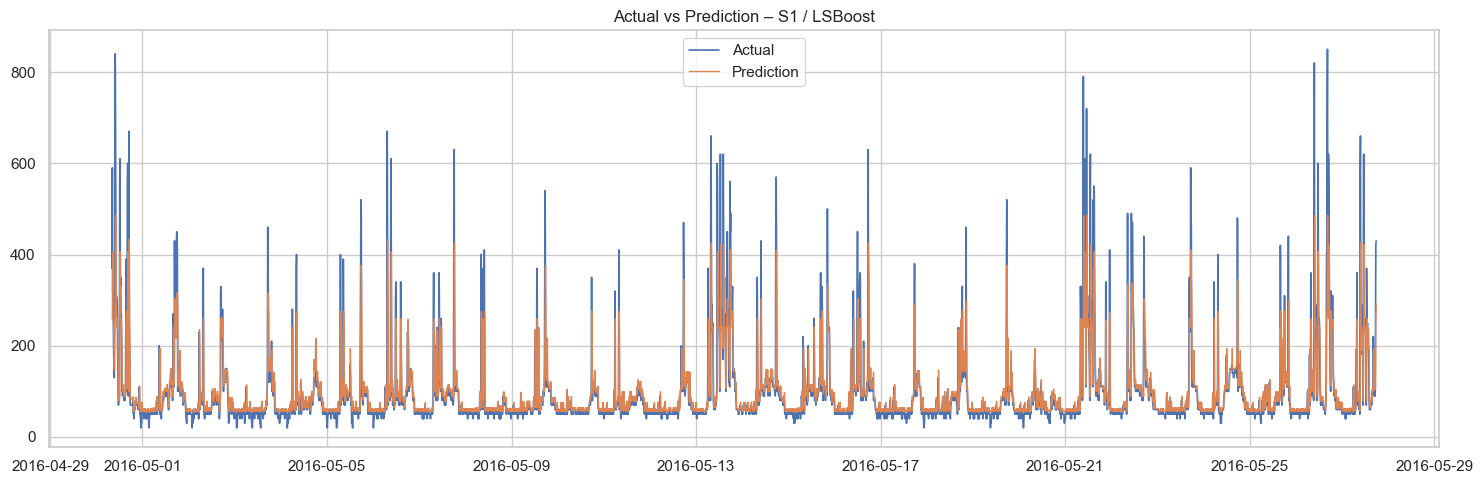

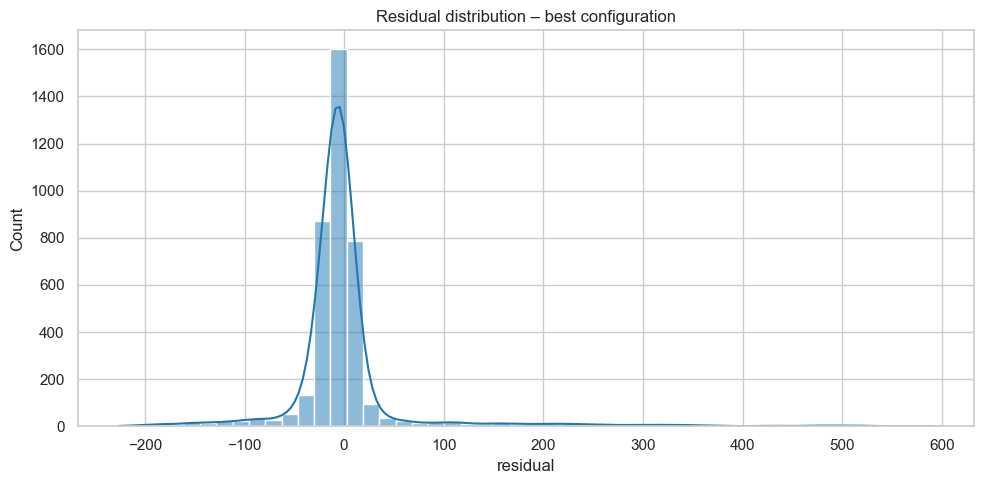

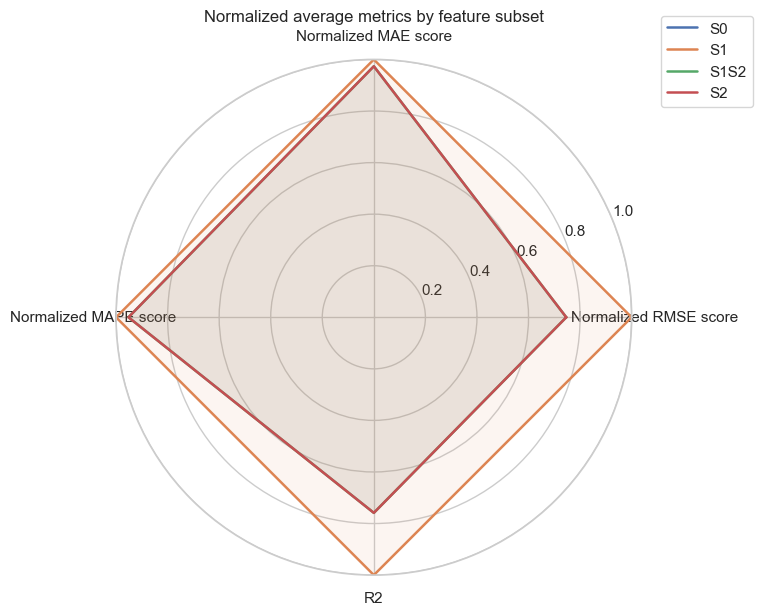

In [197]:
plt.figure(figsize=(14, 6))
sns.barplot(data=all_results.head(15), x="RMSE", y="model", hue="feature_subset", dodge=False)
plt.title("Top configurations theo RMSE trên holdout test")
plt.tight_layout()
plt.savefig(PATHS["figures"] / "top_models_rmse.png", dpi=160, bbox_inches="tight")
plt.show()

plt.figure(figsize=(10, 6))
sns.scatterplot(data=paper_results, x="n_features", y="RMSE", hue="feature_subset", style="model", s=90)
plt.title("RMSE và số lượng features – paper framework")
plt.tight_layout()
plt.savefig(PATHS["figures"] / "rmse_vs_number_of_features.png", dpi=160, bbox_inches="tight")
plt.show()

best_key = (best_row["feature_subset"], best_row["model"])
if best_row["model"] == "Persistence":
    best_pred_df = baseline_predictions_all[baseline_predictions_all["model"] == "Persistence"].copy()
elif best_row["feature_subset"] == "S0" and best_row["model"] in baseline_estimators:
    best_pred_df = baseline_predictions_all[baseline_predictions_all["model"] == best_row["model"]].copy()
else:
    best_pred_df = predictions_all[
        (predictions_all["feature_subset"] == best_key[0]) &
        (predictions_all["model"] == best_key[1])
    ].copy()

plt.figure(figsize=(15, 5))
plt.plot(best_pred_df["date"], best_pred_df["y_true"], label="Actual", linewidth=1.2)
plt.plot(best_pred_df["date"], best_pred_df["y_pred"], label="Prediction", linewidth=1.0)
plt.title(f"Actual vs Prediction – {best_key[0]} / {best_key[1]}")
plt.legend()
plt.tight_layout()
plt.savefig(PATHS["figures"] / "best_model_actual_vs_prediction.png", dpi=160, bbox_inches="tight")
plt.show()

plt.figure(figsize=(10, 5))
sns.histplot(best_pred_df["residual"], bins=50, kde=True, color="tab:blue")
plt.title("Residual distribution – best configuration")
plt.tight_layout()
plt.savefig(PATHS["figures"] / "best_model_residuals.png", dpi=160, bbox_inches="tight")
plt.show()

# Radar chart: mean normalized performance of the five ML models in each subset.
radar_metrics = ["RMSE", "MAE", "MAPE_pct_excluding_zero", "R2"]
radar_frame = paper_results.groupby("feature_subset")[radar_metrics].mean()
radar_norm = pd.DataFrame(index=radar_frame.index)
for metric in ["RMSE", "MAE", "MAPE_pct_excluding_zero"]:
    values = radar_frame[metric]
    span = values.max() - values.min()
    radar_norm[metric] = 1 - ((values - values.min()) / span if span > 0 else 0.0)
values = radar_frame["R2"]
span = values.max() - values.min()
radar_norm["R2"] = (values - values.min()) / span if span > 0 else 0.0

labels = ["Normalized RMSE score", "Normalized MAE score", "Normalized MAPE score", "R2"]
angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
angles += angles[:1]
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, polar=True)
for subset_name, row in radar_norm.iterrows():
    values = row[radar_metrics].tolist()
    values += values[:1]
    ax.plot(angles, values, linewidth=1.8, label=subset_name)
    ax.fill(angles, values, alpha=0.08)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels)
ax.set_ylim(0, 1)
ax.set_title("Normalized average metrics by feature subset")
ax.legend(loc="upper right", bbox_to_anchor=(1.25, 1.10))
plt.tight_layout()
plt.savefig(PATHS["figures"] / "feature_subset_radar_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

## 23. `SHAP` theo từng Feature Selection approach

`SHAP` được tính cho cấu hình có RMSE thấp nhất trong từng nhánh `S1`, `S2` và `S1S2`. `PermutationExplainer` được chỉ định tường minh để tránh tự động lựa chọn `ExactExplainer` với ngân sách đánh giá không đủ. `max_evals = 2M + 1` là ngân sách permutation tối thiểu theo số feature; vì vậy kết quả là ước lượng permutation SHAP, không phải Exact SHAP. Summary plot và mean absolute SHAP importance được lưu riêng cho từng nhánh.

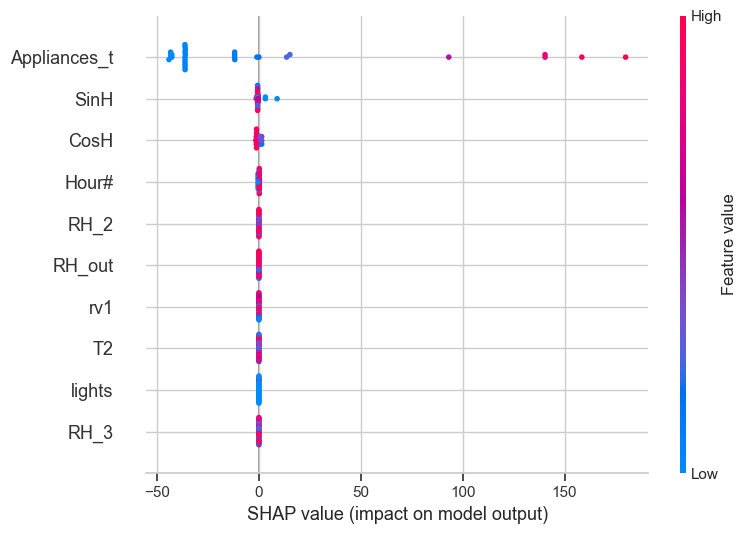

SHAP completed: S1 / LSBoost


,feature_subset,model,feature,mean_abs_SHAP
0,S1,LSBoost,Appliances_t,48.267422
3,S1,LSBoost,SinH,1.087708
9,S1,LSBoost,CosH,0.933166
6,S1,LSBoost,Hour#,0.244809
1,S1,LSBoost,RH_3,0.000000
2,S1,LSBoost,lights,0.000000
4,S1,LSBoost,T2,0.000000
5,S1,LSBoost,rv1,0.000000
7,S1,LSBoost,RH_out,0.000000
8,S1,LSBoost,RH_2,0.000000


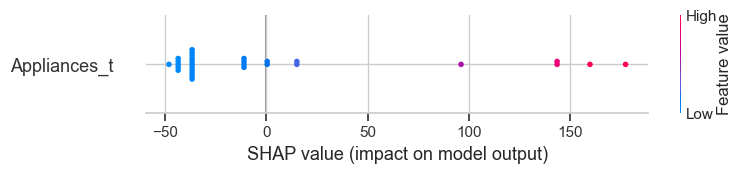

SHAP completed: S2 / LSBoost


,feature_subset,model,feature,mean_abs_SHAP
0,S2,LSBoost,Appliances_t,48.818012


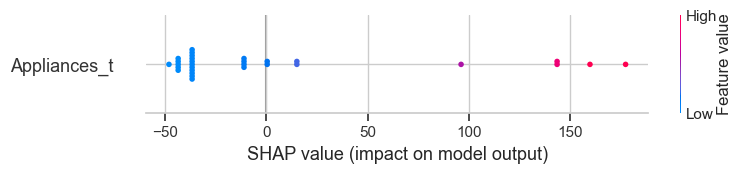

SHAP completed: S1S2 / LSBoost


,feature_subset,model,feature,mean_abs_SHAP
0,S1S2,LSBoost,Appliances_t,48.818012


,feature_subset,model,n_features,max_evals,figure
0,S1,LSBoost,10,21,D:\LMS\dubao\energy_forecasting_vscode_project...
1,S2,LSBoost,1,3,D:\LMS\dubao\energy_forecasting_vscode_project...
2,S1S2,LSBoost,1,3,D:\LMS\dubao\energy_forecasting_vscode_project...


In [198]:
shap_track_summaries = []
for subset_name in ["S1", "S2", "S1S2"]:
    subset_results = paper_results[paper_results["feature_subset"] == subset_name].copy()
    if subset_results.empty:
        print(f"Skip SHAP for {subset_name}: no result rows.")
        continue

    track_best = subset_results.sort_values(["RMSE", "MAE"]).iloc[0]
    model_name = str(track_best["model"])
    safe_model_name = model_name.replace("-", "_")
    model_path = PATHS["models"] / f"{subset_name}_{safe_model_name}.joblib"
    if not model_path.exists():
        print(f"Skip SHAP for {subset_name}: fitted estimator not found at {model_path}")
        continue

    saved = joblib.load(model_path)
    best_model_for_shap = saved["model"]
    best_features_for_shap = list(saved["features"])
    if not best_features_for_shap:
        print(f"Skip SHAP for {subset_name}: empty feature list.")
        continue

    rng = np.random.default_rng(RANDOM_SEED)
    bg_n = min(SHAP_BACKGROUND_ROWS, len(X_train))
    ex_n = min(SHAP_EXPLAIN_ROWS, len(X_test))
    bg_idx = np.sort(rng.choice(len(X_train), size=bg_n, replace=False))
    ex_idx = np.sort(rng.choice(len(X_test), size=ex_n, replace=False))
    X_background = X_train[best_features_for_shap].iloc[bg_idx]
    X_explain = X_test[best_features_for_shap].iloc[ex_idx]

    try:
        masker = shap.maskers.Independent(X_background)

        def predict_original_units(X_input, model=best_model_for_shap):
            prediction_scaled = model.predict(np.asarray(X_input, dtype=float))
            return scaler_y.inverse_transform(
                np.asarray(prediction_scaled).reshape(-1, 1)
            ).ravel()

        explainer = shap.Explainer(
            predict_original_units,
            masker,
            algorithm="permutation"
        )
        max_evals = 2 * len(best_features_for_shap) + 1
        shap_values = explainer(X_explain, max_evals=max_evals)

        plt.figure()
        shap.summary_plot(shap_values, X_explain, show=False)
        plt.tight_layout()
        figure_path = PATHS["figures"] / f"shap_summary_{subset_name}_{safe_model_name}.png"
        plt.savefig(figure_path, dpi=160, bbox_inches="tight")
        plt.show()
        plt.close()

        shap_importance = pd.DataFrame({
            "feature": best_features_for_shap,
            "mean_abs_SHAP": np.abs(shap_values.values).mean(axis=0),
        }).sort_values("mean_abs_SHAP", ascending=False)
        shap_importance.insert(0, "feature_subset", subset_name)
        shap_importance.insert(1, "model", model_name)
        shap_importance.to_csv(
            PATHS["reports"] / f"shap_feature_importance_{subset_name}.csv", index=False
        )
        joblib.dump(
            {
                "values": np.asarray(shap_values.values),
                "base_values": np.asarray(shap_values.base_values),
                "data": np.asarray(shap_values.data),
                "algorithm": "PermutationExplainer",
                "max_evals": max_evals,
                "features": best_features_for_shap,
                "model": model_name,
                "feature_subset": subset_name,
                "background_rows": bg_n,
                "explain_rows": ex_n,
                "dataset_sha256": DATASET_SHA256,
            },
            PATHS["checkpoints"] / f"shap_{subset_name}_{safe_model_name}.joblib"
        )
        shap_track_summaries.append({
            "feature_subset": subset_name,
            "model": model_name,
            "n_features": len(best_features_for_shap),
            "max_evals": max_evals,
            "figure": str(figure_path),
        })
        print(f"SHAP completed: {subset_name} / {model_name}")
        display(shap_importance)
    except Exception as exc:
        print(f"SHAP calculation failed for {subset_name}/{model_name}:", repr(exc))

shap_track_summary = pd.DataFrame(shap_track_summaries)
shap_track_summary.to_csv(PATHS["reports"] / "shap_track_summary.csv", index=False)
display(shap_track_summary)

## 24. Tổng hợp kết quả thực nghiệm

Các bảng kết quả cung cấp cơ sở so sánh accuracy và dimensionality giữa `S0`, `S1`, `S2`, `S1S2` cùng các baseline. Việc diễn giải tập trung vào thay đổi metric, số feature được giữ lại, độ ổn định giữa các model và ảnh hưởng của các sai khác triển khai. Kết quả `quick` không được sử dụng làm bằng chứng kết luận.

## 25. Checkpoint, phục hồi và sao lưu local

Artifacts được lưu sau từng model hoặc từng nhánh `SIFE`, bao gồm selected features, history, fitted estimators, metrics, predictions, figures và cấu hình thực nghiệm. `quick` và `paper` có output root riêng. Checkpoint chỉ được tải khi metadata khớp với candidate features, estimator parameters, seed và computational mode.

Bản sao lưu ZIP được tạo từ thư mục output của lần chạy hiện tại. Runtime Python không tự phục hồi biến trong RAM sau khi đóng VS Code; các cell cần được thực thi lại theo thứ tự, trong khi artifacts đã hoàn tất vẫn còn trên ổ đĩa.

In [199]:
run_manifest = {
    "created_at": datetime.now().isoformat(timespec="seconds"),
    "experiment_mode": EXPERIMENT_MODE,
    "config": CONFIG,
    "split_info": SPLIT_INFO,
    "dataset_path": str(DATA_PATH),
    "dataset_sha256": DATASET_SHA256,
    "experiment_revision": EXPERIMENT_REVISION,
    "dataset_shape_raw": list(df_raw.shape),
    "dataset_shape_supervised": list(supervised.shape),
    "n_candidate_features": len(feature_columns),
    "S1": S1,
    "S2_by_model": S2_by_model,
    "S1S2_by_model": S1S2_by_model,
    "best_configuration": best_row,
    "known_method_deviations": [
        "Dataset and target differ from the UK monthly dataset in the article.",
        "RReliefF is used as regression adaptation of Relief.",
        "SIFE is a Python port; Jaccard diversity proxies fuzzy granulation.",
        "KAG wrapper evaluation is temporally subsampled to the configured SIFE row cap.",
        "Bayesian Optimization and final SVR fits use configured temporal row caps for computational feasibility.",
        "GPR and LSBoost use scikit-learn approximations of MATLAB models.",
        "BayesSearchCV and TimeSeriesSplit replace MATLAB Bayesian Optimization.",
        "Cyclic hour and day-of-week features extend the paper's month encoding.",
        "PermutationExplainer approximates SHAP values; it is not ExactExplainer.",
    ],
}
(PATHS["reports"] / "run_manifest.json").write_text(
    json.dumps(run_manifest, ensure_ascii=False, indent=2, default=str), encoding="utf-8"
)

backup_dir = PROJECT_ROOT / "backups"
backup_dir.mkdir(parents=True, exist_ok=True)
zip_base = backup_dir / f"{PROJECT_NAME}_{EXPERIMENT_MODE}_backup"
zip_path = shutil.make_archive(str(zip_base), "zip", root_dir=RUN_ROOT)
print("Run root:", RUN_ROOT)
print("Backup ZIP:", zip_path)
print("Backup size MB:", round(Path(zip_path).stat().st_size / (1024**2), 2))

Run root: D:\LMS\dubao\energy_forecasting_vscode_project\energy_forecasting_vscode\outputs\paper
Backup ZIP: D:\LMS\dubao\energy_forecasting_vscode_project\energy_forecasting_vscode\backups\energy_forecasting_reproduction_paper_backup.zip
Backup size MB: 121.02


# GIAI ĐOẠN D — THỰC NGHIỆM MỞ RỘNG

## 27. Ablation Study: ảnh hưởng của đặc trưng Appliances_t

## 28. Robustness Study: độ bền vững trước nhiễu Gaussian

In [2]:
# ============================================================
# KHÔI PHỤC TRẠNG THÁI ABC TỪ CÁC FILE ĐÃ LƯU
# Không chạy lại Feature Selection / Bayesian Optimization
# ============================================================

from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# 1. Khai báo project root
PROJECT_ROOT = Path(
    r"D:\LMS\dubao\energy_forecasting_vscode_project\energy_forecasting_vscode"
)

RUN_ROOT = PROJECT_ROOT / "outputs" / "paper"
RANDOM_SEED = 42
TEST_SIZE = 0.20

PATHS = {
    "raw": PROJECT_ROOT / "data" / "raw",
    "processed": RUN_ROOT / "data" / "processed",
    "checkpoints": RUN_ROOT / "artifacts" / "checkpoints",
    "feature_selection": RUN_ROOT / "artifacts" / "feature_selection",
    "models": RUN_ROOT / "artifacts" / "models",
    "metrics": RUN_ROOT / "artifacts" / "metrics",
    "figures": RUN_ROOT / "figures",
    "logs": RUN_ROOT / "logs",
    "reports": RUN_ROOT / "reports",
    "config": RUN_ROOT / "config",
}

# 2. Kiểm tra các file cần khôi phục
supervised_file = PATHS["processed"] / "supervised_dataset.parquet"
scaler_file = PATHS["checkpoints"] / "scalers_and_feature_columns.joblib"
model_file = PATHS["models"] / "S1_LSBoost.joblib"
results_file = PATHS["metrics"] / "paper_models_results.csv"

required_files = [
    supervised_file,
    scaler_file,
    model_file,
    results_file,
]

for f in required_files:
    print(("FOUND  " if f.exists() else "MISSING"), f)

missing_files = [str(f) for f in required_files if not f.exists()]

if missing_files:
    raise FileNotFoundError(
        "Thiếu file kết quả đã lưu. Kiểm tra lại project root:\n"
        + "\n".join(missing_files)
    )

# 3. Nạp dataset đã được tiền xử lý
supervised = pd.read_parquet(supervised_file)

# 4. Khôi phục scaler và danh sách đặc trưng
scaler_artifact = joblib.load(scaler_file)

scaler_X = scaler_artifact["scaler_X"]
scaler_y = scaler_artifact["scaler_y"]
feature_columns = list(scaler_artifact["feature_columns"])

X_all = supervised[feature_columns].copy()
y_all = supervised["Appliances_t_plus_1"].astype(float).copy()
time_all = pd.to_datetime(supervised["date"])

# 5. Dựng lại chronological split giống ABC
split_idx = int(len(X_all) * (1 - TEST_SIZE))

X_train_raw = X_all.iloc[:split_idx].copy()
X_test_raw = X_all.iloc[split_idx:].copy()

y_train_raw = y_all.iloc[:split_idx].copy()
y_test_raw = y_all.iloc[split_idx:].copy()

time_train = time_all.iloc[:split_idx].copy()
time_test = time_all.iloc[split_idx:].copy()

# 6. Khôi phục X_train, X_test, y_train
X_train = pd.DataFrame(
    scaler_X.transform(X_train_raw),
    columns=feature_columns,
    index=X_train_raw.index,
)

X_test = pd.DataFrame(
    scaler_X.transform(X_test_raw),
    columns=feature_columns,
    index=X_test_raw.index,
)

y_train = pd.Series(
    scaler_y.transform(
        y_train_raw.to_numpy().reshape(-1, 1)
    ).ravel(),
    index=y_train_raw.index,
    name="y_scaled",
)

# 7. Nạp kết quả và mô hình S1-LSBoost đã huấn luyện
paper_results = pd.read_csv(results_file)

saved_model = joblib.load(model_file)
original_model = saved_model["model"]
s1_features = list(saved_model["features"])

# 8. Khôi phục hàm metrics đúng theo ABC
def regression_metrics(y_true, y_pred):
    yt = np.asarray(y_true, dtype=float).ravel()
    yp = np.asarray(y_pred, dtype=float).ravel()

    rmse = float(np.sqrt(mean_squared_error(yt, yp)))
    mae = float(mean_absolute_error(yt, yp))

    nonzero = np.abs(yt) > 1e-12
    mape_pct = (
        float(
            np.mean(
                np.abs((yt[nonzero] - yp[nonzero]) / yt[nonzero])
            ) * 100
        )
        if nonzero.any() else np.nan
    )

    r2 = float(r2_score(yt, yp)) if len(yt) > 1 else np.nan

    denom = float(np.sum(yp ** 2))
    rrmse = (
        float(np.sqrt(mean_squared_error(yt, yp) / denom))
        if denom > 0 else np.nan
    )

    nrmse = float(
        rmse / max(abs(np.mean(yt)), 1e-12) * 100
    )

    smape_denom = np.abs(yt) + np.abs(yp)
    valid = smape_denom > 1e-12

    smape = (
        float(
            np.mean(
                2 * np.abs(yt[valid] - yp[valid])
                / smape_denom[valid]
            ) * 100
        )
        if valid.any() else np.nan
    )

    return {
        "RMSE": rmse,
        "rRMSE_article_literal": rrmse,
        "NRMSE_mean_pct_supplement": nrmse,
        "MAPE_pct_excluding_zero": mape_pct,
        "MAPE_excluded_zero_count": int((~nonzero).sum()),
        "sMAPE_pct_supplement": smape,
        "MAE": mae,
        "R2": r2,
    }

# 9. Kiểm tra mô hình gốc có khớp kết quả đã lưu không
reference_row = paper_results[
    (paper_results["feature_subset"] == "S1")
    & (paper_results["model"] == "LSBoost")
].iloc[0]

pred_check_scaled = original_model.predict(
    X_test[s1_features]
)

pred_check = scaler_y.inverse_transform(
    np.asarray(pred_check_scaled).reshape(-1, 1)
).ravel()

check_metrics = regression_metrics(y_test_raw, pred_check)

print("\n===== RESTORE VALIDATION =====")
print("Train rows:", len(X_train))
print("Test rows:", len(X_test))
print("Candidate features:", len(feature_columns))
print("S1 features:", s1_features)
print("Saved RMSE:", reference_row["RMSE"])
print("Recomputed RMSE:", check_metrics["RMSE"])

if not np.isclose(
    check_metrics["RMSE"],
    reference_row["RMSE"],
    rtol=1e-4,
    atol=1e-4
):
    raise RuntimeError(
        "RMSE không khớp kết quả đã lưu. "
        "Dừng thực nghiệm mở rộng để kiểm tra dữ liệu/checkpoint."
    )

# 10. Tạo thư mục mở rộng riêng
EXT_ROOT = RUN_ROOT / "extended_experiments"
E1_DIR = EXT_ROOT / "E1_lag_ablation"
E2_DIR = EXT_ROOT / "E2_gaussian_robustness"

E1_DIR.mkdir(parents=True, exist_ok=True)
E2_DIR.mkdir(parents=True, exist_ok=True)

print("\nRESTORE SUCCESSFUL")
print("E1 output:", E1_DIR)
print("E2 output:", E2_DIR)

FOUND   D:\LMS\dubao\energy_forecasting_vscode_project\energy_forecasting_vscode\outputs\paper\data\processed\supervised_dataset.parquet
FOUND   D:\LMS\dubao\energy_forecasting_vscode_project\energy_forecasting_vscode\outputs\paper\artifacts\checkpoints\scalers_and_feature_columns.joblib
FOUND   D:\LMS\dubao\energy_forecasting_vscode_project\energy_forecasting_vscode\outputs\paper\artifacts\models\S1_LSBoost.joblib
FOUND   D:\LMS\dubao\energy_forecasting_vscode_project\energy_forecasting_vscode\outputs\paper\artifacts\metrics\paper_models_results.csv

===== RESTORE VALIDATION =====
Train rows: 15787
Test rows: 3947
Candidate features: 36
S1 features: ['Appliances_t', 'RH_3', 'lights', 'SinH', 'T2', 'rv1', 'Hour#', 'RH_out', 'RH_2', 'CosH']
Saved RMSE: 61.22399657772537
Recomputed RMSE: 61.22399657772537

RESTORE SUCCESSFUL
E1 output: D:\LMS\dubao\energy_forecasting_vscode_project\energy_forecasting_vscode\outputs\paper\extended_experiments\E1_lag_ablation
E2 output: D:\LMS\dubao\energy

d:\LMS\dubao\energy_forecasting_vscode_project\energy_forecasting_vscode\.venv\Lib\site-packages\sklearn\base.py:486: UserWarning: X has feature names, but GradientBoostingRegressor was fitted without feature names
  warnings.warn(


Original S1 features: 10
No-lag S1 features: 9
Removed: Appliances_t


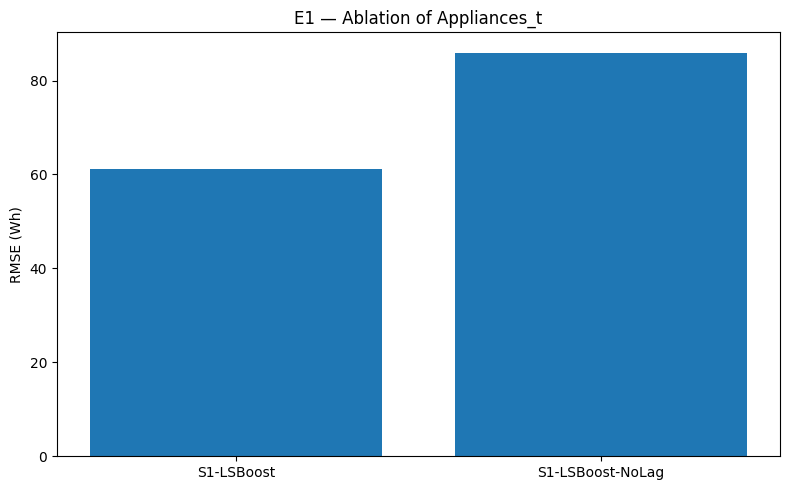

,experiment,n_features,removed_Appliances_t,RMSE,rRMSE_article_literal,NRMSE_mean_pct_supplement,MAPE_pct_excluding_zero,MAPE_excluded_zero_count,sMAPE_pct_supplement,MAE,R2,RMSE_change_pct
0,S1-LSBoost,10,False,61.223997,0.008350,63.525530,24.249230,0,21.392815,26.543855,0.547735,0.000000
1,S1-LSBoost-NoLag,9,True,85.967090,0.012836,89.198766,51.080773,0,40.257089,47.974735,0.108310,40.414046



E1 COMPLETED
Output: D:\LMS\dubao\energy_forecasting_vscode_project\energy_forecasting_vscode\outputs\paper\extended_experiments\E1_lag_ablation


In [3]:
# ============================================================
# E1 — LAG FEATURE ABLATION STUDY
# S1-LSBoost vs S1-LSBoost without Appliances_t
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.base import clone
from pathlib import Path

# 1. Xác định đặc trưng
s1_features = list(saved_model["features"])

assert "Appliances_t" in s1_features

no_lag_features = [
    f for f in s1_features
    if f != "Appliances_t"
]

print("Original S1 features:", len(s1_features))
print("No-lag S1 features:", len(no_lag_features))
print("Removed: Appliances_t")

# 2. Mô hình gốc
X_test_original = X_test[s1_features].to_numpy(dtype=float)

pred_original_scaled = original_model.predict(
    X_test_original
)

pred_original = scaler_y.inverse_transform(
    np.asarray(pred_original_scaled).reshape(-1, 1)
).ravel()

metrics_original = regression_metrics(
    y_test_raw,
    pred_original
)

# 3. Huấn luyện lại cùng cấu hình LSBoost,
#    nhưng loại Appliances_t
X_train_no_lag = X_train[no_lag_features].to_numpy(dtype=float)
X_test_no_lag = X_test[no_lag_features].to_numpy(dtype=float)

no_lag_model = clone(original_model)

no_lag_model.fit(
    X_train_no_lag,
    y_train.to_numpy()
)

pred_no_lag_scaled = no_lag_model.predict(
    X_test_no_lag
)

pred_no_lag = scaler_y.inverse_transform(
    np.asarray(pred_no_lag_scaled).reshape(-1, 1)
).ravel()

metrics_no_lag = regression_metrics(
    y_test_raw,
    pred_no_lag
)

# 4. Kiểm tra RMSE mô hình gốc
reference_rmse = float(
    paper_results.loc[
        (paper_results["feature_subset"] == "S1") &
        (paper_results["model"] == "LSBoost"),
        "RMSE"
    ].iloc[0]
)

assert np.isclose(
    metrics_original["RMSE"],
    reference_rmse,
    rtol=1e-4,
    atol=1e-4
), "RMSE của mô hình gốc không khớp paper mode."

# 5. Tổng hợp kết quả
e1_results = pd.DataFrame([
    {
        "experiment": "S1-LSBoost",
        "n_features": len(s1_features),
        "removed_Appliances_t": False,
        **metrics_original
    },
    {
        "experiment": "S1-LSBoost-NoLag",
        "n_features": len(no_lag_features),
        "removed_Appliances_t": True,
        **metrics_no_lag
    }
])

e1_results["RMSE_change_pct"] = (
    (e1_results["RMSE"] - metrics_original["RMSE"])
    / metrics_original["RMSE"] * 100
)

# 6. Lưu kết quả
E1_DIR.mkdir(parents=True, exist_ok=True)

e1_results.to_csv(
    E1_DIR / "lag_ablation_results.csv",
    index=False
)

pd.DataFrame({
    "test_index": y_test_raw.index,
    "y_true": y_test_raw.to_numpy(),
    "pred_original": pred_original,
    "pred_no_lag": pred_no_lag
}).to_csv(
    E1_DIR / "lag_ablation_predictions.csv",
    index=False
)

joblib.dump(
    {
        "model": no_lag_model,
        "features": no_lag_features,
        "experiment": "S1-LSBoost-NoLag"
    },
    E1_DIR / "S1_LSBoost_NoLag.joblib"
)

# 7. Biểu đồ
plt.figure(figsize=(8, 5))

plt.bar(
    e1_results["experiment"],
    e1_results["RMSE"]
)

plt.ylabel("RMSE (Wh)")
plt.title("E1 — Ablation of Appliances_t")
plt.tight_layout()

plt.savefig(
    E1_DIR / "lag_ablation_rmse.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

display(e1_results)

print("\nE1 COMPLETED")
print("Output:", E1_DIR)

d:\LMS\dubao\energy_forecasting_vscode_project\energy_forecasting_vscode\.venv\Lib\site-packages\sklearn\base.py:486: UserWarning: X has feature names, but GradientBoostingRegressor was fitted without feature names
  warnings.warn(
d:\LMS\dubao\energy_forecasting_vscode_project\energy_forecasting_vscode\.venv\Lib\site-packages\sklearn\base.py:486: UserWarning: X has feature names, but GradientBoostingRegressor was fitted without feature names
  warnings.warn(
d:\LMS\dubao\energy_forecasting_vscode_project\energy_forecasting_vscode\.venv\Lib\site-packages\sklearn\base.py:486: UserWarning: X has feature names, but GradientBoostingRegressor was fitted without feature names
  warnings.warn(
d:\LMS\dubao\energy_forecasting_vscode_project\energy_forecasting_vscode\.venv\Lib\site-packages\sklearn\base.py:486: UserWarning: X has feature names, but GradientBoostingRegressor was fitted without feature names
  warnings.warn(
d:\LMS\dubao\energy_forecasting_vscode_project\energy_forecasting_vscode


Evaluating noise level: 0%
  Repeat 1/5: RMSE=61.2240
  Repeat 2/5: RMSE=61.2240
  Repeat 3/5: RMSE=61.2240
  Repeat 4/5: RMSE=61.2240
  Repeat 5/5: RMSE=61.2240

Evaluating noise level: 5%
  Repeat 1/5: RMSE=74.6435
  Repeat 2/5: RMSE=74.2858
  Repeat 3/5: RMSE=73.5125
  Repeat 4/5: RMSE=73.5922
  Repeat 5/5: RMSE=73.3713

Evaluating noise level: 10%
  Repeat 1/5: RMSE=93.0747
  Repeat 2/5: RMSE=92.5640
  Repeat 3/5: RMSE=92.2425
  Repeat 4/5: RMSE=92.6811
  Repeat 5/5: RMSE=91.0553

Evaluating noise level: 20%
  Repeat 1/5: RMSE=125.7032
  Repeat 2/5: RMSE=124.1856
  Repeat 3/5: RMSE=124.6650
  Repeat 4/5: RMSE=125.2954
  Repeat 5/5: RMSE=123.4579


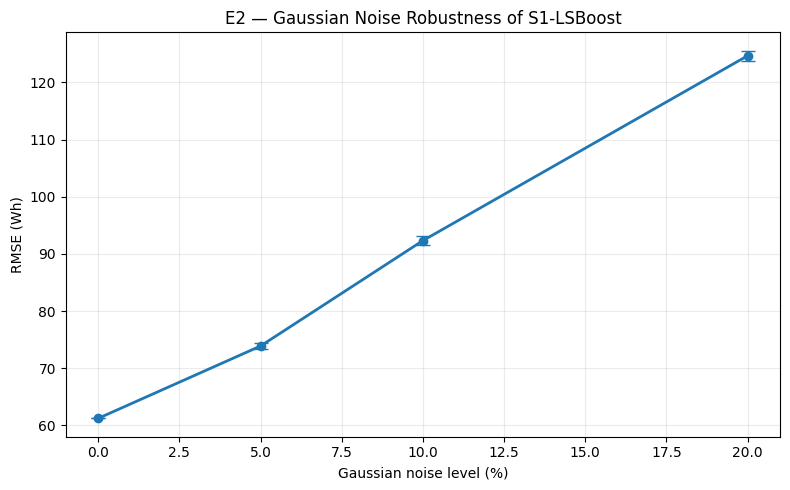

,noise_level,noise_percent,RMSE_mean,RMSE_std,MAE_mean,MAE_std,R2_mean,R2_std,RMSE_increase_pct
0,0.00,0.0,61.223997,0.000000,26.543855,0.000000,0.547735,0.000000,0.000000
1,0.05,5.0,73.881087,0.553236,44.871392,0.269007,0.341379,0.009880,20.673414
2,0.10,10.0,92.323538,0.768936,61.843262,0.677536,-0.028486,0.017070,50.796326
3,0.20,20.0,124.661407,0.889108,86.439267,1.044853,-0.875129,0.026731,103.615272



E2 completed.
Saved to: D:\LMS\dubao\energy_forecasting_vscode_project\energy_forecasting_vscode\outputs\paper\extended_experiments\E2_gaussian_robustness


In [4]:
# ============================================================
# E2 — GAUSSIAN NOISE ROBUSTNESS
# Evaluate S1-LSBoost under noisy test inputs
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Cấu hình
NOISE_LEVELS = [0.00, 0.05, 0.10, 0.20]
NOISE_REPEATS = 5

# Sử dụng đúng mô hình S1-LSBoost đã kiểm tra ở E1
noise_model = original_model
noise_features = list(s1_features)

X_clean = X_test.loc[:, noise_features].copy()
y_true = y_test_raw.to_numpy()

# 2. Đánh giá dữ liệu sạch
clean_pred_scaled = noise_model.predict(X_clean)

clean_pred = scaler_y.inverse_transform(
    np.asarray(clean_pred_scaled).reshape(-1, 1)
).ravel()

clean_metrics = regression_metrics(y_true, clean_pred)

# 3. Thực nghiệm Gaussian noise
noise_rows = []

for noise_level in NOISE_LEVELS:

    print(f"\nEvaluating noise level: {noise_level:.0%}")

    for repeat in range(NOISE_REPEATS):

        rng = np.random.default_rng(
            RANDOM_SEED + repeat
        )

        if noise_level == 0:
            X_noisy = X_clean.copy()
        else:
            noise = rng.normal(
                loc=0.0,
                scale=noise_level,
                size=X_clean.shape
            )

            X_noisy = X_clean + noise

        # Không clipping về [0, 1]:
        # test values có thể nằm ngoài range train
        # và cần được giữ nguyên như dữ liệu gốc.
        pred_scaled = noise_model.predict(X_noisy)

        pred = scaler_y.inverse_transform(
            np.asarray(pred_scaled).reshape(-1, 1)
        ).ravel()

        metrics = regression_metrics(y_true, pred)

        noise_rows.append({
            "noise_level": noise_level,
            "noise_percent": noise_level * 100,
            "repeat": repeat + 1,
            **metrics
        })

        print(
            f"  Repeat {repeat + 1}/{NOISE_REPEATS}: "
            f"RMSE={metrics['RMSE']:.4f}"
        )

# 4. Lưu kết quả từng lần chạy
noise_raw = pd.DataFrame(noise_rows)

noise_raw.to_csv(
    E2_DIR / "gaussian_noise_all_runs.csv",
    index=False
)

# 5. Tổng hợp mean và standard deviation
noise_summary = (
    noise_raw
    .groupby(["noise_level", "noise_percent"])
    .agg(
        RMSE_mean=("RMSE", "mean"),
        RMSE_std=("RMSE", "std"),
        MAE_mean=("MAE", "mean"),
        MAE_std=("MAE", "std"),
        R2_mean=("R2", "mean"),
        R2_std=("R2", "std"),
    )
    .reset_index()
)

# Mức thay đổi RMSE so với clean
clean_rmse = clean_metrics["RMSE"]

noise_summary["RMSE_increase_pct"] = (
    (noise_summary["RMSE_mean"] - clean_rmse)
    / clean_rmse * 100
)

noise_summary.to_csv(
    E2_DIR / "gaussian_noise_summary.csv",
    index=False
)

# 6. Vẽ biểu đồ robustness
plt.figure(figsize=(8, 5))

plt.errorbar(
    noise_summary["noise_percent"],
    noise_summary["RMSE_mean"],
    yerr=noise_summary["RMSE_std"].fillna(0),
    marker="o",
    capsize=5,
    linewidth=2
)

plt.xlabel("Gaussian noise level (%)")
plt.ylabel("RMSE (Wh)")
plt.title("E2 — Gaussian Noise Robustness of S1-LSBoost")
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    E2_DIR / "gaussian_noise_robustness.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

# 7. Xuất thông tin mô hình và cấu hình
noise_config = {
    "model": "S1-LSBoost",
    "features": noise_features,
    "noise_levels": NOISE_LEVELS,
    "repeats_per_level": NOISE_REPEATS,
    "random_seed": RANDOM_SEED,
    "input_noise": "Additive Gaussian noise on MinMax-scaled test features",
    "target_unchanged": True,
    "model_retrained": False,
}

import json

with open(
    E2_DIR / "gaussian_noise_config.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(noise_config, f, ensure_ascii=False, indent=2)

display(noise_summary)

print("\nE2 completed.")
print("Saved to:", E2_DIR)


===== E1_lag_ablation =====
lag_ablation_predictions.csv             189.43 KB
lag_ablation_results.csv                 0.51 KB
lag_ablation_rmse.png                    25.08 KB
S1_LSBoost_NoLag.joblib                  269.62 KB

===== E2_gaussian_robustness =====
gaussian_noise_all_runs.csv              3.01 KB
gaussian_noise_config.json               0.43 KB
gaussian_noise_robustness.png            58.82 KB
gaussian_noise_summary.csv               0.60 KB


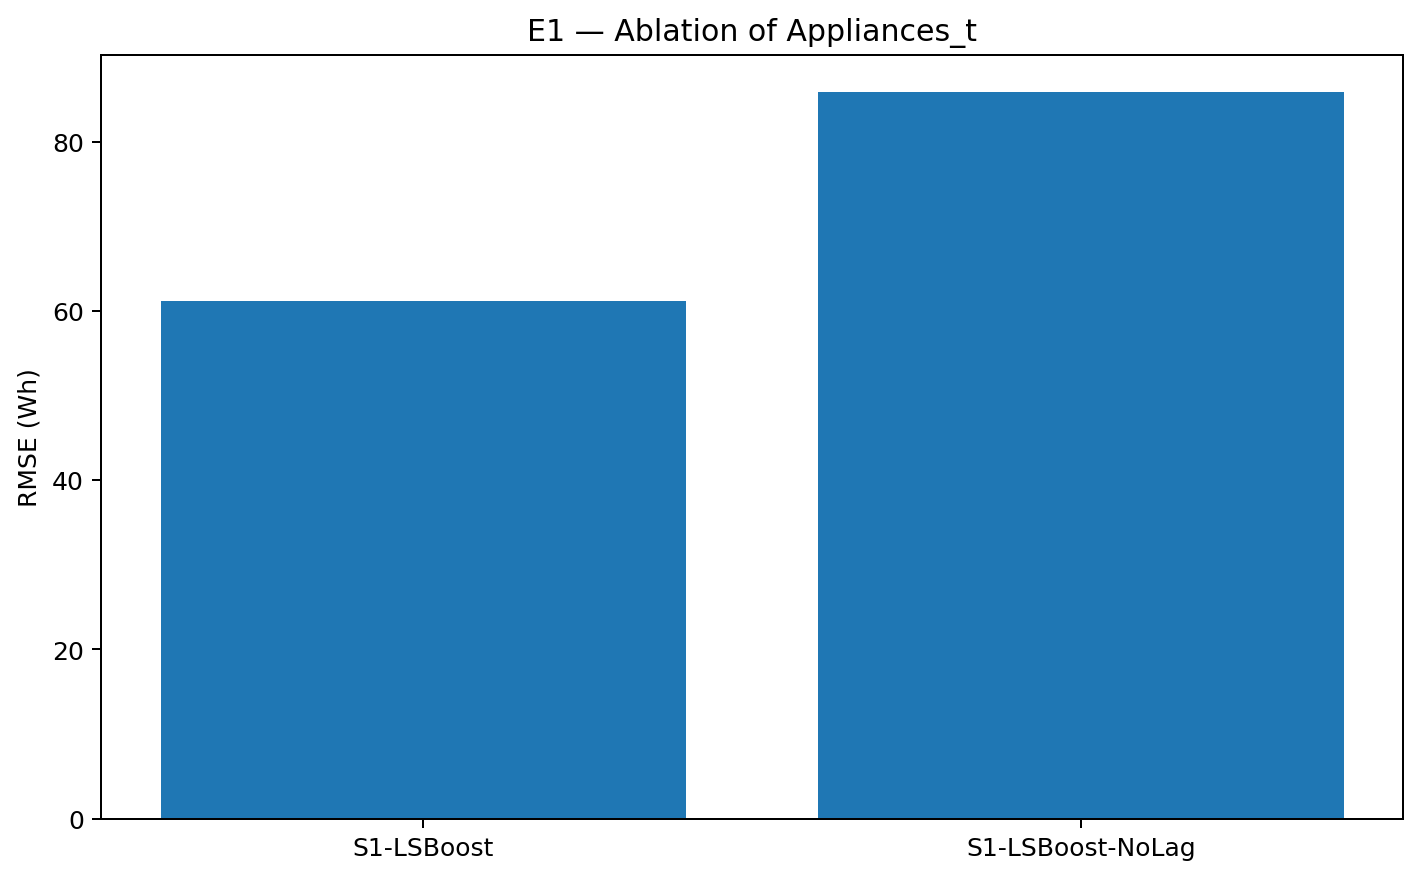

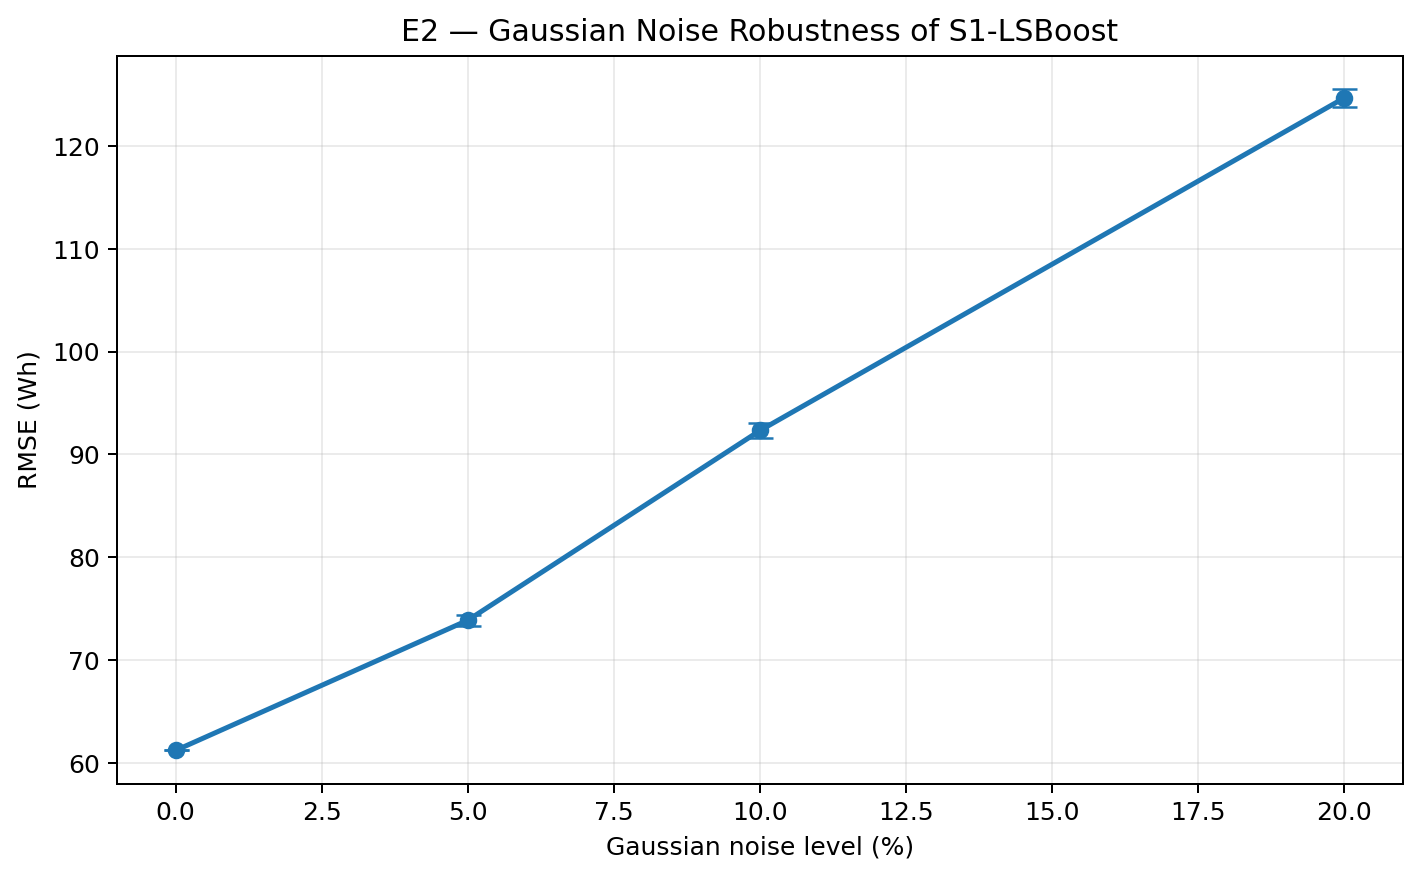

In [5]:
from pathlib import Path

for folder in [E1_DIR, E2_DIR]:
    print(f"\n===== {folder.name} =====")

    for f in sorted(folder.glob("*")):
        if f.is_file():
            print(
                f"{f.name:40s}",
                f"{f.stat().st_size / 1024:.2f} KB"
            )

# Hiển thị hai biểu đồ đã lưu
from IPython.display import display, Image

display(Image(filename=str(E1_DIR / "lag_ablation_rmse.png")))
display(Image(filename=str(E2_DIR / "gaussian_noise_robustness.png")))

## 26. Kết luận phương pháp và tài liệu tham chiếu

Đây là method reproduction trên `KAG_energydata_complete.csv`, không phải replication dữ liệu và kết quả của nghiên cứu gốc. Các điểm khác biệt gồm domain dataset, target, sampling frequency, temporal features, regression adaptation của `Relief`, Python port của `SIFE`, ánh xạ MATLAB models sang scikit-learn và implementation của Bayesian Optimization. `rRMSE_article_literal` giữ cách diễn giải trực tiếp công thức Eq. (21); `NRMSE_mean_pct_supplement` là metric bổ sung. Không so sánh trực tiếp trị số metric KAG với Table 7 của bài báo.

### Tài liệu tham chiếu

1. Eskandari, H., Saadatmand, H., Ramzan, M., & Mousapour, M. (2024). *Innovative framework for accurate and transparent forecasting of energy consumption: A fusion of feature selection and interpretable machine learning*. Applied Energy, 366, 123314. https://doi.org/10.1016/j.apenergy.2024.123314
2. Saadatmand, H., & Akbarzadeh-T, M.-R. (2023). *Set-based integer-coded fuzzy granular evolutionary algorithms for high-dimensional feature selection*. Applied Soft Computing, 142, 110240. https://doi.org/10.1016/j.asoc.2023.110240
3. MathWorks. `relieff` documentation — regression response and `RReliefF`: https://www.mathworks.com/help/stats/relieff.html